# 🛡️ Cálculo do Risco das Ações e da Carteira (2015–2022, estendido até 2025)

**Autor:** Rafael R. Silva · **Metodologia:** CRISP-DM · **Tipo de problema:** análise de risco financeiro (sem modelo preditivo)

> **Resumo:** medimos o **risco** de 5 ações da B3 (GOL, CVC, WEG, Magazine Luiza e Totvs) e do **BOVA11** entre 2015 e 2022: quanto cada uma oscila, quanto pode cair, quanto se perde num dia ruim e se juntar as 5 numa carteira é mais ou menos arriscado que comprar o índice.

---

### 📑 Sumário
- **FASE 01:** Entendimento do Negócio
- **FASE 02:** Preparação dos Dados
- **FASE 03:** Indicadores de Risco
- **FASE 04:** Avaliação
- **FASE 05:** Implantação
- **Resposta à pergunta de negócio**, **Insights**, **Próximos Passos** e **Interface com Streamlit**

> ℹ️ **Sobre esta versão (v2):** a versão original continua no repositório para mostrar a evolução. Ela lia o **retorno logarítmico como se fosse percentual** (a CVC aparecia com "−121,94%", uma perda impossível), media o risco pelo desvio de só **8 retornos anuais**, usava o coeficiente de variação com **média negativa** e concluía sobre o risco da carteira **sem olhar o retorno**. A v2 corrige esses pontos e acrescenta **semivolatilidade, maior queda, VaR e CVaR**, **beta**, **contribuição de cada ação para o risco**, um **backtest do VaR** (janela móvel e EWMA) com os testes de Kupiec e Christoffersen, **VaR de 10 dias e de 99%**, **testes de estresse** com crises reais, **intervalos de confiança por bootstrap**, uma carteira de **mínima variância testada fora da amostra**, o **Índice de Sharpe** contra o CDI, testes estatísticos com tamanho de efeito e **testes automatizados** das funções. A Fase 04 (item 1.2) estende a análise até **2025** e compara o risco **antes, durante e depois da Covid**. Executado com Python 3.13 e pandas 3.

# FASE 01: ENTENDIMENTO DO NEGÓCIO

## 🏢 Contexto

Retorno é só metade da história de um investimento. A outra metade é o **risco**: quanto o valor oscila no caminho, quanto pode cair e quanto se perde num dia ruim. Duas ações com o mesmo retorno podem ser investimentos muito diferentes se uma delas cair 90% no meio do caminho.

Esta é a **parte 2** do estudo. A [parte 1](https://github.com/RafaelSilva89/Analise_do_Comportamento_da_Carteira_de_Acoes-Financas_parte_1) mediu o **retorno** da carteira; aqui medimos o **risco** das mesmas ações, no mesmo período (2015–2022, com a recessão de 2015–2016 e a pandemia de 2020).

| Ação | Empresa (setor) |
|---|---|
| **GOL** | Gol Linhas Aéreas (aviação) |
| **CVC** | CVC Brasil (turismo) |
| **WEGE** | WEG (máquinas e equipamentos elétricos) |
| **MGLU** | Magazine Luiza (varejo) |
| **TOTS** | Totvs (software) |
| **BOVA** | BOVA11: fundo que replica o Ibovespa (**referência**) |

**Fonte dos dados:** Yahoo Finance (biblioteca `yfinance`) e Banco Central (CDI).

## 🎯 Objetivo

Medir o risco de cada ação e de uma carteira com as 5 ações, e compará-los com o mercado (BOVA11).

> **Pergunta de negócio:** *Quanto risco cada ação carrega? Uma carteira com as 5 ações, com o mesmo peso em cada, é mais arriscada do que investir no BOVA11? Esse risco extra foi recompensado, e quanto se pode perder num dia ruim?*

**Stakeholder:** gerente do departamento financeiro / investidor pessoa física.

## 🧩 Formato da solução

| Item | Definição |
|---|---|
| **Granularidade** | Retorno diário de cada ativo (um registro por pregão) |
| **Tipo de problema** | Análise de risco histórico. **Não há modelo de Machine Learning**; a única "previsão" é o VaR (a perda máxima esperada para o dia seguinte), que é testado fora da amostra |
| **Indicadores** | Volatilidade, semivolatilidade, maior queda, **VaR** e **CVaR**, beta, correlação, risco da carteira e contribuição de cada ação, **Índice de Sharpe** |
| **Entrega** | Relatório (notebook + README), tabela de indicadores em `reports/`, ficha em JSON e um **app Streamlit** para calcular o risco de qualquer combinação de pesos |

## 🗺️ Planejamento da solução (CRISP-DM)

| Fase | O que será feito |
|---|---|
| **01. Entendimento do negócio** | Definir a pergunta e as medidas de risco |
| **02. Preparação dos dados** | Ler os preços, conferir a qualidade, explorar com 7 hipóteses (com testes estatísticos) e criar os retornos |
| **03. Indicadores de risco** | Calcular cada medida, comparar com as da versão original, montar a carteira e testar o VaR fora da amostra (*backtest*) |
| **04. Avaliação** | VaR previsto x perda observada na pandemia e contribuição de cada ação para o risco |
| **05. Implantação** | Salvar os indicadores, a ficha e simular carteiras com dados novos (app Streamlit) |

> 💡 O roteiro CRISP-DM foi pensado para projetos de Machine Learning. Como este projeto é uma **análise de risco**, a Fase 03 foi adaptada para o **cálculo dos indicadores**. Onde o roteiro de modelos tem um equivalente real em risco, ele foi usado: a separação treino/teste vira **estimação (2015–2019) x teste (2020–2022)** do VaR, a calibração vira o **backtest de Kupiec** e o teste anti-vazamento mostra o que acontece quando o VaR **olha o futuro**. As etapas sem equivalente aparecem com **"🚫 Não se aplica"** e o motivo.

# FASE 02: PREPARAÇÃO DOS DADOS

Nesta fase vamos carregar os preços, conferir a qualidade da base, explorar o risco das ações com hipóteses e criar os retornos diários.

## 1 - COLETA DOS DADOS

### 1.1. Bibliotecas

In [1]:
import sys

import numpy             as np
import pandas            as pd
import seaborn           as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy import stats

import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)

#### Funções auxiliares

As funções reutilizáveis ficam na pasta **`src/`** do projeto (também usadas pelo app Streamlit):

| Arquivo | Funções | Para que serve |
|---|---|---|
| `src/config.py` | `PREGOES_POR_ANO`, `NIVEL_VAR`, `JANELA_VAR`, `FIM_ESTIMACAO`, `LAMBDA_EWMA`, `CENARIOS_ESTRESSE`, `PERIODOS_COVID`, `SEMENTE`, caminhos | Convenções e parâmetros num lugar só |
| `src/financas.py` | `baixar_precos` / `carregar_precos`, `baixar_cdi` / `carregar_cdi` | Baixa ou lê os preços e o CDI |
| `src/financas.py` | `retorno_total`, `cagr`, `retorno_por_ano`, `volatilidade`, `maior_queda`, `indice_sharpe`, `simular_carteira`, `salvar_ficha` | Indicadores de retorno e de risco (reaproveitados da parte 1) e a ficha em JSON |
| `src/financas.py` | `classificar_periodo`, `ativos_com_dados` | Fases da Covid e ativos com dados em cada período (extensão até 2025) |
| `src/risco.py` | `retornos_diarios`, `semivolatilidade`, `var_historico`, `var_parametrico`, `cvar`, `beta`, `volatilidade_movel` | Medidas de risco de cada ativo |
| `src/risco.py` | `covariancia_anual`, `volatilidade_carteira`, `contribuicao_risco`, `razao_diversificacao`, `retorno_carteira_pesos_fixos`, `valor_carteira_pesos_fixos` | Risco de uma carteira e de onde ele vem |
| `src/risco.py` | `var_movel`, `volatilidade_ewma`, `var_ewma`, `violacoes_var`, `teste_kupiec`, `teste_christoffersen` | VaR estimado só com o passado e o backtest |
| `src/risco.py` | `var_horizonte`, `choques_cenario`, `perda_cenario`, `pesos_minima_variancia`, `indice_sharpe_retornos` | VaR de vários dias, testes de estresse, carteira de mínima variância e Sharpe para o bootstrap |
| `src/estatistica.py` | `teste_levene`, `teste_kruskal`, `teste_mann_whitney`, `teste_normalidade`, `teste_binomial`, `teste_wilcoxon`, `teste_spearman`, `regra_iqr` | Testes das hipóteses, sempre com tamanho de efeito, e a regra do IQR |
| `src/estatistica.py` | `bootstrap_blocos` | Intervalo de confiança por bootstrap em blocos (séries temporais) |
| `src/graficos.py` | `plot_linhas`, `plot_barras`, `plot_heatmap`, `salvar` | Gráficos padronizados, salvos em `Imagens/` |

> ✅ As funções de `src/` têm **testes automatizados** em `tests/` (rodar `pytest` na raiz do projeto). Exemplo: numa carteira de dois ativos sem correlação e com a mesma volatilidade, metade em cada, o risco precisa cair para 1/√2 (~71%) do risco de um ativo.

In [2]:
sys.path.append('..')  # permite importar a pasta src/ a partir de Notebooks/

from src.config import (ACOES, REFERENCIA, PASTA_DADOS, PASTA_REPORTS, PREGOES_POR_ANO, NIVEL_VAR, JANELA_VAR,
                        FIM_ESTIMACAO, LAMBDA_EWMA, CENARIOS_ESTRESSE, SEMENTE, N_BOOTSTRAP, BLOCO_BOOTSTRAP,
                        PERIODOS_COVID)
from src.financas import (TICKERS, baixar_precos, baixar_cdi, carregar_precos, carregar_cdi, anos_no_periodo,
                          retorno_total, cagr, retorno_por_ano, volatilidade, maior_queda, indice_sharpe,
                          simular_carteira, salvar_ficha, classificar_periodo, ativos_com_dados)
from src.risco import (retornos_diarios, semivolatilidade, var_historico, var_parametrico, cvar, beta,
                       volatilidade_movel, covariancia_anual, volatilidade_carteira, contribuicao_risco,
                       razao_diversificacao, retorno_carteira_pesos_fixos, valor_carteira_pesos_fixos, var_movel,
                       var_ewma, violacoes_var, teste_kupiec, teste_christoffersen, var_horizonte, choques_cenario,
                       perda_cenario, pesos_minima_variancia, indice_sharpe_retornos)
from src.estatistica import (teste_levene, teste_kruskal, teste_mann_whitney, teste_normalidade, teste_binomial,
                             teste_wilcoxon, teste_spearman, regra_iqr, bootstrap_blocos)
from src.graficos import plot_linhas, plot_barras, plot_heatmap, salvar, titulo, CORES

### 1.2. Salvar a base em CSV

As bases ficam salvas em `Datasets/` para que o resultado seja **reproduzível** (os dados da internet mudam ou somem):

| Arquivo | Fonte | Conteúdo |
|---|---|---|
| `acoes.csv` | Yahoo Finance | Preço de **fechamento** diário dos 6 ativos. É a mesma base da versão original e da parte 1 |
| `cdi.csv` | Banco Central (série 12 do SGS) | Taxa diária do **CDI**, a referência de "investimento sem risco" para o Índice de Sharpe. Copiado da parte 1 |

Para baixar tudo de novo, basta mudar `ATUALIZAR_DADOS` para `True`.

> ⚠️ A versão original também tinha um arquivo `stocks.csv`, que **nenhuma célula usava**. Conferindo, ele tem sábados, domingos e feriados (a bolsa não abre), valores negativos e passos diários com desvio de exatamente ~1,00 em todas as colunas: é um **passeio aleatório simulado** com nomes de ações, sem relação com os preços reais. ✅ Na v2 ele foi **removido** do repositório (continua no histórico do git) para não ser confundido com dados reais.

In [3]:
ATUALIZAR_DADOS = False   # True baixa as bases novamente (precisa de internet e da biblioteca yfinance)

if ATUALIZAR_DADOS:
    baixar_precos(TICKERS, coluna='Close').to_csv(PASTA_DADOS / 'acoes.csv')
    baixar_cdi().to_csv(PASTA_DADOS / 'cdi.csv')

precos = carregar_precos(PASTA_DADOS / 'acoes.csv')
cdi = carregar_cdi(PASTA_DADOS / 'cdi.csv', precos.index)   # valor de R$ 1 aplicado no CDI, nas datas dos pregões

## 2 - LIMPEZA DOS DADOS

Antes de medir qualquer risco, conferimos se a base está completa e coerente.

### 2.1. Leitura dos dados

In [4]:
precos.head()

,GOL,CVC,WEGE,MGLU,TOTS,BOVA
Date,,,,,,
2015-01-02,14.99,15.20,5.923076,0.232812,11.910702,47.259998
2015-01-05,14.85,15.00,5.963461,0.237187,11.544731,46.320000
2015-01-06,15.21,14.80,5.875000,0.234062,10.822770,46.580002
2015-01-07,14.55,14.67,5.807692,0.241875,10.746248,48.150002
2015-01-08,14.27,14.15,5.905769,0.240000,10.995774,48.509998


#### 📖 Dicionário de dados

| Coluna | Descrição |
|---|---|
| `Date` (índice) | Data do pregão. Fins de semana e feriados não aparecem, pois a bolsa não abre |
| `GOL`, `CVC`, `WEGE`, `MGLU`, `TOTS`, `BOVA` | **Preço de fechamento** (em R$) de cada ativo no dia, já ajustado por desdobramentos |

> ℹ️ Para medir risco usamos os **retornos diários** (variação percentual de um dia para o outro), e não os preços. Dividendos quase não mudam a oscilação diária; o efeito deles sobre o retorno foi medido na parte 1.

### 2.2. Colunas

In [5]:
print(f'Tickers originais: {list(TICKERS)}')
print(f'Nomes usados:      {precos.columns.tolist()}')

Tickers originais: ['GOLL4.SA', 'CVCB3.SA', 'WEGE3.SA', 'MGLU3.SA', 'TOTS3.SA', 'BOVA11.SA']
Nomes usados:      ['GOL', 'CVC', 'WEGE', 'MGLU', 'TOTS', 'BOVA']


### 2.3. Dimensões de dados

In [6]:
print(f'Pregões: {precos.shape[0]} | Ativos: {precos.shape[1]}')
print(f'Período: {precos.index.min():%d/%m/%Y} a {precos.index.max():%d/%m/%Y} ({anos_no_periodo(precos):.2f} anos)')
print()
print('Pregões por ano:')
print(precos.groupby(precos.index.year).size().to_string())

Pregões: 1988 | Ativos: 6
Período: 02/01/2015 a 29/12/2022 (7.99 anos)

Pregões por ano:
Date
2015    246
2016    249
2017    254
2018    246
2019    248
2020    248
2021    247
2022    250


📌 **Nota**
- 🔎 São **1.988 pregões** de **6 ativos**, de 02/01/2015 a 29/12/2022 (**8 anos**).
- 🔎 Cada ano tem entre **246 e 254 pregões**. A versão original usava 246 como número fixo para anualizar o risco.
- ✅ **Decisão:** usar **252 pregões**, a convenção de mercado e a mesma da parte 1. A diferença nos números é pequena (item 3 da Fase 03), mas deixa os resultados comparáveis com relatórios e outros estudos.

### 2.4. Check dados nulos

In [7]:
precos.isnull().sum()

GOL     0
CVC     0
WEGE    0
MGLU    0
TOTS    0
BOVA    0
dtype: int64

✅ Nenhum valor nulo: todos os ativos têm preço em todos os pregões do período.

### 2.5. Estatística descritiva

#### 2.5.1. Separando os tipos de variáveis

In [8]:
precos.dtypes

GOL     float64
CVC     float64
WEGE    float64
MGLU    float64
TOTS    float64
BOVA    float64
dtype: object

Todas as colunas são **numéricas** (preços em R$), e a data está no índice.

#### 2.5.2. Colunas numéricas

In [9]:
precos.describe().round(2)

,GOL,CVC,WEGE,MGLU,TOTS,BOVA
count,1988.00,1988.00,1988.00,1988.00,1988.00,1988.00
mean,15.31,28.04,16.95,6.76,17.89,81.84
std,9.33,16.24,12.48,7.63,9.39,23.96
min,1.16,3.66,4.94,0.03,7.16,36.45
25%,7.90,15.00,6.74,0.41,10.07,60.08
50%,13.93,21.90,9.38,3.91,12.34,82.70
75%,20.99,43.09,30.29,10.28,27.07,103.07
max,43.79,64.80,46.10,27.45,40.60,125.75


📌 **Nota**
- 🔎 Os preços estão em escalas muito diferentes: a MGLU variou de **R$ 0,03 a R$ 27,45** e o BOVA11 de **R$ 36,45 a R$ 125,75**.
- ⚠️ A versão original usava o desvio padrão do **preço** como medida de risco ("a CVC tem média de 28,04 e varia em torno de 16 reais e 24 centavos"). Mas esse desvio depende do nível do preço e da tendência: o BOVA11 tem o maior desvio (**23,96**) e é justamente o ativo **menos** arriscado (H1).
- ✅ Na v2, o risco é medido pelos **retornos** (variação percentual de um dia para o outro), que são comparáveis entre ativos de qualquer preço.

#### 2.5.3. Colunas Categóricas

> 🚫 **Não se aplica.** A base não tem colunas categóricas: só a data (índice) e os preços.

### 2.6. Verificando outliers

Em ações, um "outlier" não é um erro de dado: são os **dias de movimento extremo**, e eles são exatamente o risco que queremos medir. Por isso olhamos os **retornos diários**, e não os preços.

In [10]:
retornos = retornos_diarios(precos)

extremos = pd.DataFrame({
    'Maior queda em 1 dia': retornos.min(),
    'Data da queda': retornos.idxmin().dt.strftime('%d/%m/%Y'),
    'Maior alta em 1 dia': retornos.max(),
    'Data da alta': retornos.idxmax().dt.strftime('%d/%m/%Y'),
})
extremos.style.format({'Maior queda em 1 dia': '{:.1%}', 'Maior alta em 1 dia': '{:+.1%}'})

,Maior queda em 1 dia,Data da queda,Maior alta em 1 dia,Data da alta
GOL,-36.3%,12/03/2020,+50.3%,01/02/2016
CVC,-34.8%,18/03/2020,+32.4%,26/03/2020
WEGE,-20.6%,16/03/2020,+13.9%,22/07/2020
MGLU,-21.1%,12/03/2020,+37.3%,28/12/2015
TOTS,-15.3%,18/03/2020,+19.8%,25/03/2020
BOVA,-14.6%,12/03/2020,+13.4%,13/03/2020


In [11]:
# Regra do IQR nos retornos diários: fora de [Q1 - 1,5·IQR ; Q3 + 1,5·IQR]
iqr_retornos = pd.DataFrame({ativo: regra_iqr(retornos[ativo]) for ativo in retornos}).T
iqr_retornos.style.format({'limite inferior': '{:+.1%}', 'limite superior': '{:+.1%}', 'outliers': '{:.0f}',
                           '% outliers': '{:.1%}'})

,limite inferior,limite superior,outliers,% outliers
GOL,-9.4%,+9.1%,90,4.5%
CVC,-6.8%,+6.7%,119,6.0%
WEGE,-4.8%,+4.9%,63,3.2%
MGLU,-8.0%,+8.1%,112,5.6%
TOTS,-5.3%,+5.4%,75,3.8%
BOVA,-3.4%,+3.6%,63,3.2%


📌 **Nota: dias extremos e regra do IQR**
- 🔎 As **maiores quedas em um único dia** de todos os ativos aconteceram entre **12 e 18/03/2020**, no início da pandemia: GOL **−36,3%**, CVC **−34,8%**, BOVA11 **−14,6%**.
- 🔎 Pela regra do IQR, de **3,2%** (WEGE e BOVA11) a **6,0%** (CVC) dos pregões são outliers. Numa curva normal seriam ~0,7%: primeiro sinal de "caudas gordas" (H3).
- 🔎 A "oscilação normal" de um dia vai de cerca de **±3,5%** no BOVA11 a **±9%** na GOL.
- ✅ **Decisão:** manter todos os dias. São movimentos reais e são o próprio risco que queremos medir; removê-los faria as ações parecerem mais seguras do que são.

### 2.7. Verificando o balanceamento da variável alvo

> 🚫 **Não se aplica.** Não há variável alvo nem classes: o projeto mede o risco histórico das ações.

### 🛡️ Remoção de variáveis com vazamento (*data leakage*)

> 🚫 **Não há variável a remover**, porque não há alvo. Mas existe um vazamento típico de **risco**: estimar a perda máxima de um dia (VaR) usando dados **do futuro**, inclusive do próprio dia. Na v2, todo VaR usado como previsão é calculado **só com os pregões anteriores** (`var_movel` usa `shift(1)`), e o item 9 da Fase 03 mostra o que acontece quando essa regra é quebrada.

## 3 - ANÁLISE EXPLORATÓRIA DOS DADOS

A medida básica de risco é a **volatilidade**: o desvio padrão dos retornos diários, levado para a escala de um ano. Uma volatilidade de 30% significa, grosso modo, que num ano "típico" o preço oscila cerca de 30% para cima ou para baixo em torno da tendência.

### 3.1. Criação das Hipóteses

| # | Hipótese | Tipo |
|---|---|---|
| H1 | O BOVA11 é o ativo menos volátil: cada ação sozinha oscila mais que o índice | Individual |
| H2 | O risco disparou na pandemia (2020) | Individual |
| H3 | Os retornos têm "caudas gordas": dias extremos acontecem muito mais do que a curva normal prevê | Individual |
| H4 | A correlação entre as ações sobe nos dias de estresse (a diversificação falha quando mais se precisa dela) | Combinada |
| H5 | Diversificar reduz o risco: a carteira com as 5 ações oscila menos que a média das ações | Combinada |
| H6 | A carteira é mais arriscada que o BOVA11, mas o risco extra foi recompensado | Combinada |
| H7 | No período, quem oscilou mais não rendeu mais | Combinada |

> 💡 Em todos os testes, **o que importa é o tamanho do efeito, não o p**: com quase 2 mil pregões, diferenças pequenas já dão p-valores minúsculos.

### 3.2. Hipóteses Individuais (colunas isoladas)

#### H1 – O BOVA11 é o ativo menos volátil

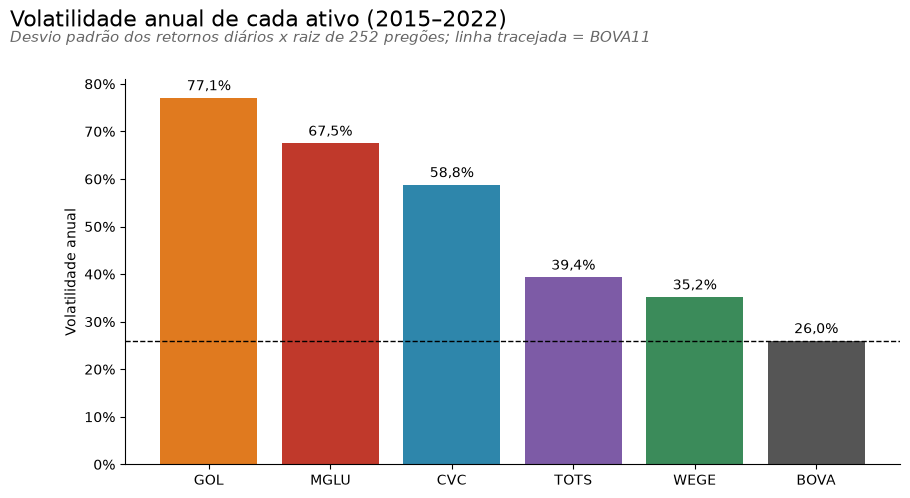

In [12]:
volatilidades = volatilidade(precos).sort_values(ascending=False)
plot_barras(volatilidades, 'Volatilidade anual de cada ativo (2015–2022)', 'Volatilidade por ativo',
            ylabel='Volatilidade anual', referencia=volatilidades[REFERENCIA],
            subtitulo='Desvio padrão dos retornos diários x raiz de 252 pregões; linha tracejada = BOVA11')

**Teste.** Brown-Forsythe (Levene pela mediana) entre os retornos diários de cada ação e os do BOVA11. O tamanho do efeito é a **razão entre os desvios**: 2 = a ação oscila o dobro do índice.

In [13]:
pd.DataFrame({acao: teste_levene(retornos[acao], retornos[REFERENCIA]) for acao in ACOES}).T

,teste,estatística,p-valor,efeito,tamanho do efeito
GOL,Brown-Forsythe,594.844621,0.0,razão de desvios,2.96289
CVC,Brown-Forsythe,360.489908,0.0,razão de desvios,2.260224
WEGE,Brown-Forsythe,107.780586,0.0,razão de desvios,1.353027
MGLU,Brown-Forsythe,549.788702,0.0,razão de desvios,2.595636
TOTS,Brown-Forsythe,191.339555,0.0,razão de desvios,1.512827


✅ **Verdadeira.** O BOVA11 tem a menor volatilidade (**26,0%** ao ano). Todas as ações oscilam mais, de **35,2%** (WEGE) a **77,1%** (GOL).
- 💡 O BOVA11 é uma cesta com dezenas de empresas: a queda de umas é compensada pela alta de outras. É a diversificação funcionando (H5).

🧪 **Teste estatístico:** Brown-Forsythe com p < 0,001 para as 5 ações. O que importa é o tamanho do efeito, não o p: a GOL oscila **2,96 vezes** mais que o BOVA11, a MGLU **2,60**, a CVC **2,26**, a TOTS **1,51** e a WEGE **1,35** vez.

#### H2 – O risco disparou na pandemia (2020)

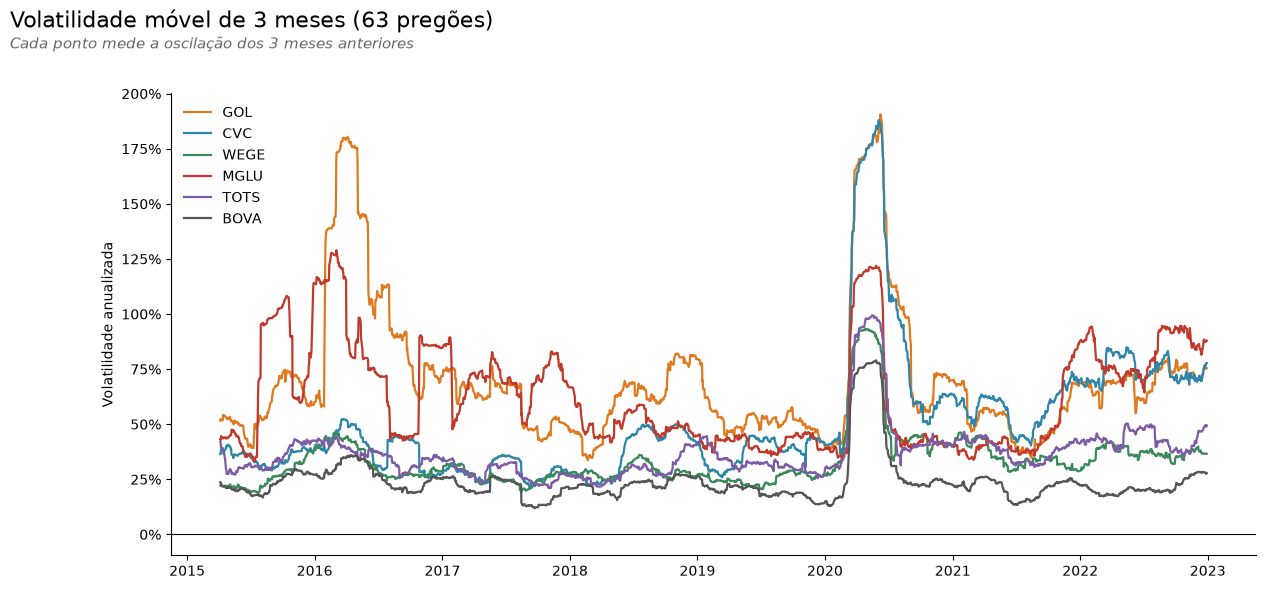

,GOL,CVC,WEGE,MGLU,TOTS,BOVA
Date,,,,,,
2015,2.78%,1.74%,1.34%,3.32%,1.80%,1.15%
2016,4.73%,1.81%,1.58%,2.80%,1.69%,1.29%
2017,2.57%,1.37%,1.26%,3.28%,1.28%,0.87%
2018,3.10%,1.95%,1.39%,2.27%,1.45%,1.08%
2019,2.32%,1.71%,1.30%,2.00%,1.52%,0.87%
2020,4.50%,4.38%,2.50%,2.79%,2.49%,1.77%
2021,2.55%,2.89%,1.61%,2.59%,1.91%,1.06%
2022,3.38%,3.63%,1.79%,4.13%,2.17%,1.08%


In [14]:
vol_movel = volatilidade_movel(retornos)
plot_linhas(vol_movel.dropna(), 'Volatilidade móvel de 3 meses (63 pregões)', 'Volatilidade movel',
            ylabel='Volatilidade anualizada', percentual=True,
            subtitulo='Cada ponto mede a oscilação dos 3 meses anteriores')

oscilacao_ano = retornos.abs().groupby(retornos.index.year).mean()
oscilacao_ano.style.format('{:.2%}').background_gradient(cmap='Reds', axis=0)

**Teste.** Kruskal-Wallis do **tamanho do movimento diário** (|retorno|) entre os 8 anos, com épsilon² como tamanho de efeito, e Mann-Whitney entre 2020 e 2015–2019, com a correlação de postos.

In [15]:
movimento = retornos.abs().stack().rename('movimento').reset_index()
movimento['ano'] = movimento['Date'].dt.year

pd.DataFrame({
    'Kruskal (8 anos)': teste_kruskal(movimento['movimento'], movimento['ano']),
    'Mann-Whitney (2020 x 2015–19)': teste_mann_whitney(movimento.loc[movimento['ano'] == 2020, 'movimento'],
                                                        movimento.loc[movimento['ano'] < 2020, 'movimento']),
}).T

,teste,estatística,p-valor,efeito,tamanho do efeito
Kruskal (8 anos),Kruskal-Wallis,299.631416,0.0,épsilon²,0.025135
Mann-Whitney (2020 x 2015–19),Mann-Whitney,6658317.5,0.0,correlação de postos,0.200933


✅ **Verdadeira.** Em 2020, o movimento médio de um dia cresceu em todos os ativos, de **+40%** (MGLU) a **+156%** (CVC) em relação a 2019: o BOVA11 passou de **0,87%** (2019) para **1,77%**, a WEGE de **1,30%** para **2,50%** e a CVC de **1,71%** para **4,38%**. No gráfico, a volatilidade de 3 meses atinge o pico entre **abril e junho de 2020** (a janela ainda carrega o choque de março).
- 💡 Para CVC e GOL (viagens), o risco **não voltou** ao nível de antes: em 2022, a CVC ainda se movia **3,63%** por dia, o dobro de 2019.

🧪 **Teste estatístico:** Kruskal-Wallis entre os 8 anos com p < 0,001, mas épsilon² de só **0,025** (efeito pequeno): o ano explica pouco da variação de um dia para o outro, que é muito ruidosa. Comparando 2020 com 2015–2019, o Mann-Whitney dá correlação de postos de **0,20** (efeito pequeno a moderado). O que importa é o tamanho do efeito, não o p.

#### H3 – Os retornos têm "caudas gordas"

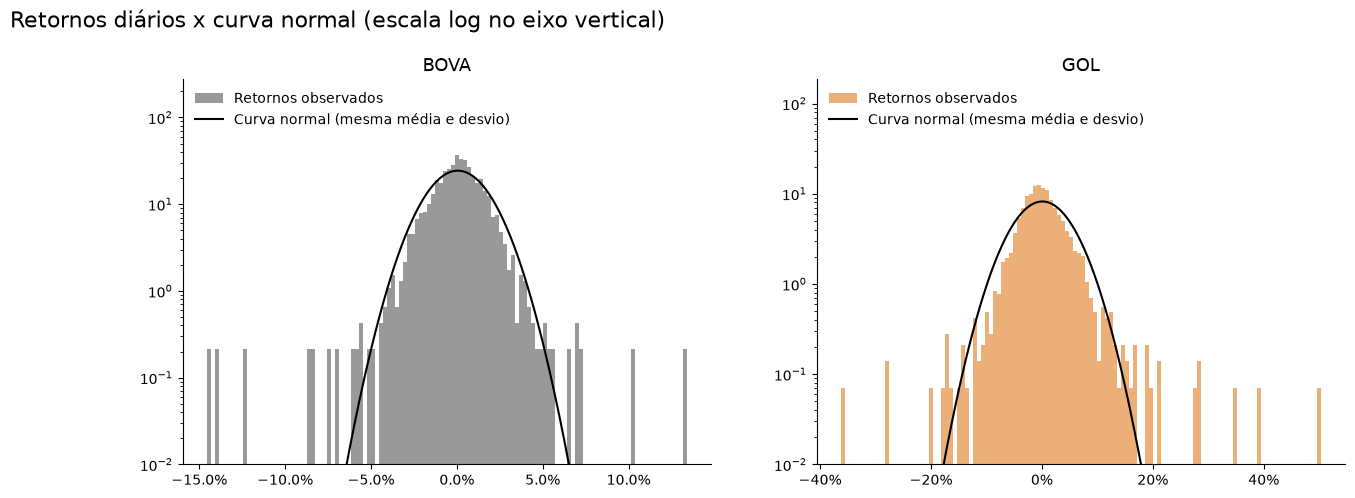

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5))
for ax, ativo in zip(axs, ['BOVA', 'GOL']):
    serie = retornos[ativo]
    ax.hist(serie, bins=120, density=True, color=CORES[ativo], alpha=0.6, label='Retornos observados')
    x = np.linspace(serie.min(), serie.max(), 400)
    ax.plot(x, stats.norm.pdf(x, serie.mean(), serie.std()), color='black', lw=1.5, label='Curva normal (mesma média e desvio)')
    ax.set_yscale('log')
    ax.set_ylim(bottom=0.01)
    ax.set_title(ativo, fontsize=13)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.legend(frameon=False, loc='upper left')
    sns.despine(ax=ax)
titulo('Retornos diários x curva normal (escala log no eixo vertical)')
salvar('Caudas gordas')
plt.show()

**Teste.** Jarque-Bera (a distribuição é normal?) com a **curtose em excesso** como efeito (0 na normal), e teste binomial dos dias com movimento **maior que 3 desvios padrão**: na normal, seriam só 0,27% dos pregões.

In [17]:
padronizado = (retornos - retornos.mean()) / retornos.std()
dias_3_desvios = (padronizado.abs() > 3).sum()

caudas = pd.DataFrame({ativo: teste_normalidade(retornos[ativo]) for ativo in retornos}).T
caudas['dias além de 3 desvios'] = dias_3_desvios
caudas['% dos pregões'] = dias_3_desvios / len(retornos)
caudas['vezes o esperado na normal'] = [teste_binomial(dias, len(retornos), 0.0027)['tamanho do efeito']
                                        for dias in dias_3_desvios]
caudas['p-valor binomial'] = [teste_binomial(dias, len(retornos), 0.0027)['p-valor'] for dias in dias_3_desvios]
caudas

,teste,estatística,p-valor,efeito,tamanho do efeito,dias além de 3 desvios,% dos pregões,vezes o esperado na normal,p-valor binomial
GOL,Jarque-Bera,17161.773636,0.0,curtose em excesso,14.22094,31,0.015601,5.778300,2.402069e-14
CVC,Jarque-Bera,15891.67732,0.0,curtose em excesso,13.844443,31,0.015601,5.778300,2.402069e-14
WEGE,Jarque-Bera,4695.097477,0.0,curtose em excesso,7.523528,21,0.010569,3.914332,2.379110e-07
MGLU,Jarque-Bera,6083.985865,0.0,curtose em excesso,8.361311,30,0.015098,5.591903,1.414471e-13
TOTS,Jarque-Bera,2244.556367,0.0,curtose em excesso,5.206606,22,0.011072,4.100729,5.679674e-08
BOVA,Jarque-Bera,11327.443404,0.0,curtose em excesso,11.624838,23,0.011575,4.287126,1.297885e-08


In [18]:
# Consequência prática: a perda de um dia ruim pela curva normal x pelo histórico
var_comparado = pd.DataFrame({
    'VaR 95% histórico': var_historico(retornos, 0.95),
    'VaR 95% pela normal': var_parametrico(retornos, 0.95),
    'VaR 99% histórico': var_historico(retornos, 0.99),
    'VaR 99% pela normal': var_parametrico(retornos, 0.99),
})
var_comparado.style.format('{:.2%}')

,VaR 95% histórico,VaR 95% pela normal,VaR 99% histórico,VaR 99% pela normal
GOL,6.44%,7.91%,11.80%,11.22%
CVC,5.04%,6.08%,9.50%,8.61%
WEGE,3.21%,3.53%,4.96%,5.04%
MGLU,5.75%,6.78%,10.71%,9.68%
TOTS,3.60%,4.01%,6.30%,5.69%
BOVA,2.35%,2.64%,3.94%,3.76%


✅ **Verdadeira.** Todos os ativos têm "caudas gordas":
- 🔎 A curtose em excesso vai de **5,2** (TOTS) a **14,2** (GOL); na curva normal ela é **0**.
- 🔎 Os dias com movimento maior que 3 desvios padrão foram de **1,06%** (WEGE) a **1,56%** (GOL e CVC) dos pregões: **3,9 a 5,8 vezes** o que a normal prevê (0,27%).
- 🔎 **Consequência prática:** no VaR de 95%, a curva normal até **exagera** a perda (GOL: 7,91% pela normal x 6,44% no histórico), porque a maioria dos dias é mais calma do que a normal supõe. Mas no VaR de **99%** ela **subestima** a perda em 5 dos 6 ativos (GOL: 11,22% x **11,80%**; CVC: 8,61% x **9,50%**; MGLU: 9,68% x **10,71%**).
- ✅ **Decisão:** usar o **VaR histórico** (calculado com os dias que aconteceram), e não a fórmula da curva normal.

🧪 **Teste estatístico:** Jarque-Bera com p < 0,001 em todos os ativos e teste binomial dos dias além de 3 desvios com p < 0,001. O que importa é o tamanho do efeito: dias extremos de **4 a 6 vezes** mais frequentes do que na curva normal.

### 3.3. Hipóteses Combinadas (entre colunas)

#### H4 – A correlação entre as ações sobe nos dias de estresse

A **correlação** (de −1 a 1) mede o quanto duas ações sobem e caem **juntas**. Quanto menor, mais uma compensa a outra. Comparamos a correlação nos **dias normais** e nos **10% piores dias do mercado** (BOVA11).

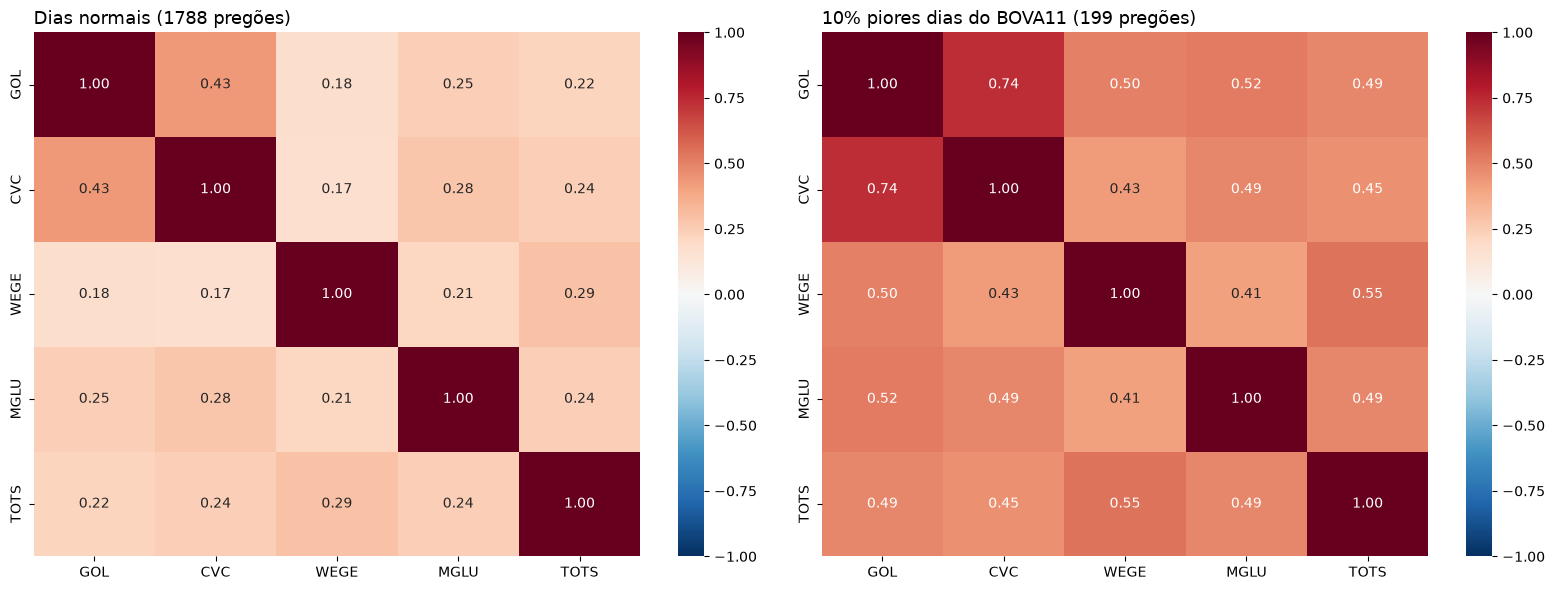

Correlação média entre as ações: 0.25 nos dias normais x 0.51 nos dias de estresse
Pares em que a correlação subiu: 10 de 10


In [19]:
estresse = retornos[REFERENCIA] <= retornos[REFERENCIA].quantile(0.10)   # 10% piores dias do BOVA11
pares = [(a, b) for i, a in enumerate(ACOES) for b in ACOES[i + 1:]]

corr_normal = retornos.loc[~estresse, ACOES].corr()
corr_estresse = retornos.loc[estresse, ACOES].corr()
correlacao_pares = pd.DataFrame({'Dias normais': [corr_normal.loc[a, b] for a, b in pares],
                                 'Dias de estresse': [corr_estresse.loc[a, b] for a, b in pares]},
                                index=[f'{a}–{b}' for a, b in pares])

fig, axs = plt.subplots(1, 2, figsize=(16, 6))
plot_heatmap(corr_normal, f'Dias normais ({(~estresse).sum()} pregões)', None, ax=axs[0])
plot_heatmap(corr_estresse, f'10% piores dias do BOVA11 ({estresse.sum()} pregões)', None, ax=axs[1])
plt.tight_layout()
salvar('Correlacao normal x estresse')
plt.show()

print(f"Correlação média entre as ações: {correlacao_pares['Dias normais'].mean():.2f} nos dias normais"
      f" x {correlacao_pares['Dias de estresse'].mean():.2f} nos dias de estresse")
print(f"Pares em que a correlação subiu: {(correlacao_pares['Dias de estresse'] > correlacao_pares['Dias normais']).sum()} de {len(pares)}")

**Teste.** Wilcoxon pareado nos 10 pares de ações (o mesmo par, nos dias normais e nos de estresse), com a mediana da diferença como efeito. Como conferência, repetimos a comparação separando os dias pela **volatilidade do mercado** (acima ou abaixo da mediana), um critério que não depende do retorno do próprio dia.

In [20]:
display(pd.Series(teste_wilcoxon(correlacao_pares['Dias normais'], correlacao_pares['Dias de estresse'])).to_frame('H4').T)

vol_mercado = vol_movel[REFERENCIA]
agitado = vol_mercado > vol_mercado.median()
media_pares = lambda matriz: np.mean([matriz.loc[a, b] for a, b in pares])
print(f"Conferência pela volatilidade do mercado: correlação média de {media_pares(retornos.loc[agitado, ACOES].corr()):.2f}"
      f" em períodos agitados x {media_pares(retornos.loc[vol_mercado.notna() & ~agitado, ACOES].corr()):.2f} em períodos calmos")

,teste,estatística,p-valor,efeito,tamanho do efeito
H4,Wilcoxon pareado,0.0,0.001953,mediana da diferença,0.256937


Conferência pela volatilidade do mercado: correlação média de 0.39 em períodos agitados x 0.32 em períodos calmos


✅ **Verdadeira.** Nos dias normais, a correlação média entre as 5 ações é **0,25**. Nos **10% piores dias do BOVA11**, ela dobra para **0,51**, e subiu em **10 dos 10 pares**.
- 💡 Ou seja, a diversificação protege **menos** justamente quando o mercado cai: nos dias ruins, quase tudo cai junto.
- ⚠️ Parte desse aumento é mecânica: escolher os dias em que o mercado caiu muito já seleciona dias em que as ações caíram juntas. Por isso conferimos com um critério que não depende do retorno do dia, a **volatilidade do mercado**: a correlação também sobe, de **0,32** em períodos calmos para **0,39** em períodos agitados. O efeito é menor, mas vai na mesma direção.

🧪 **Teste estatístico:** Wilcoxon pareado nos 10 pares com p de **0,002** e mediana do aumento de **+0,26** na correlação. Com só 10 pares o teste tem pouca força, mas todos os pares mudaram no mesmo sentido.

#### H5 – Diversificar reduz o risco

Se as ações não andam 100% juntas, a carteira oscila **menos** que a média das ações. A **razão de diversificação** mede esse ganho: média ponderada das volatilidades ÷ volatilidade da carteira (1 = nenhum ganho).

In [21]:
pesos_iguais = {acao: 0.2 for acao in ACOES}
cov_acoes = covariancia_anual(retornos[ACOES])

media_ponderada = (volatilidade(precos[ACOES]) * 0.2).sum()
vol_carteira = volatilidade_carteira(pesos_iguais, cov_acoes)
print(f'Média ponderada das volatilidades das 5 ações: {media_ponderada:.1%}')
print(f'Volatilidade da carteira (20% em cada):        {vol_carteira:.1%}')
print(f'Razão de diversificação:                       {razao_diversificacao(pesos_iguais, cov_acoes):.2f}')

diversificacao_ano = pd.DataFrame({
    ano: {'Média ponderada das ações': (grupo[ACOES].std() * np.sqrt(PREGOES_POR_ANO) * 0.2).sum(),
          'Carteira (20% em cada)': volatilidade_carteira(pesos_iguais, covariancia_anual(grupo[ACOES]))}
    for ano, grupo in retornos.groupby(retornos.index.year)
}).T
diversificacao_ano['Redução do risco'] = 1 - diversificacao_ano['Carteira (20% em cada)'] / diversificacao_ano['Média ponderada das ações']
diversificacao_ano.style.format('{:.1%}')

Média ponderada das volatilidades das 5 ações: 55.6%
Volatilidade da carteira (20% em cada):        39.6%
Razão de diversificação:                       1.40


,Média ponderada das ações,Carteira (20% em cada),Redução do risco
2015,48.2%,28.4%,41.1%
2016,59.8%,37.3%,37.7%
2017,41.7%,27.9%,33.0%
2018,42.6%,30.0%,29.7%
2019,36.9%,23.9%,35.3%
2020,81.7%,66.3%,18.8%
2021,48.5%,35.0%,27.9%
2022,62.1%,49.3%,20.6%


**Teste.** Wilcoxon pareado nos 8 anos: a carteira oscilou menos que a média ponderada das ações no **mesmo ano**?

In [22]:
pd.Series(teste_wilcoxon(diversificacao_ano['Média ponderada das ações'],
                         diversificacao_ano['Carteira (20% em cada)'])).to_frame('H5').T

,teste,estatística,p-valor,efeito,tamanho do efeito
H5,Wilcoxon pareado,0.0,0.007812,mediana da diferença,-0.136343


✅ **Verdadeira.** A média ponderada das volatilidades das 5 ações é **55,6%**, mas a carteira oscila só **39,6%**: a diversificação cortou **29%** do risco (razão de diversificação de **1,40**).
- 🔎 A carteira oscilou menos que a média das ações em **todos os 8 anos**, com redução de **18,8%** (2020) a **41,1%** (2015).
- 💡 O ano com **menor** ganho de diversificação foi **2020**, o da crise, confirmando a H4: quando as correlações sobem, diversificar protege menos.

🧪 **Teste estatístico:** Wilcoxon pareado nos 8 anos com p de **0,008** e mediana da diferença de **−13,6 pontos percentuais** de volatilidade. Com 8 anos o teste tem pouca força, mas a carteira ganhou nos 8.

#### H6 – A carteira é mais arriscada que o BOVA11, mas o risco foi recompensado

A versão original comparou só o **risco** da carteira (20% em cada ação) com o do BOVA11. Aqui olhamos também o **retorno** e o **Índice de Sharpe** contra o CDI:

> **Sharpe = (CAGR − CAGR do CDI) ÷ volatilidade**: quanto de retorno acima da renda fixa cada unidade de risco entregou.

Como na fórmula da versão original, a carteira mantém os pesos de 20% **todos os dias** (o efeito de comprar e manter é visto no item 7 da Fase 03).

,Volatilidade anual,Maior queda,CAGR,Índice de Sharpe,R$ 1 virou
Carteira (20% em cada),39.6%,-65.8%,18.1%,0.24,R$ 3.78
BOVA11,26.0%,-46.9%,10.6%,0.08,R$ 2.24
CDI,0.3%,0.0%,8.6%,0.00,R$ 1.93


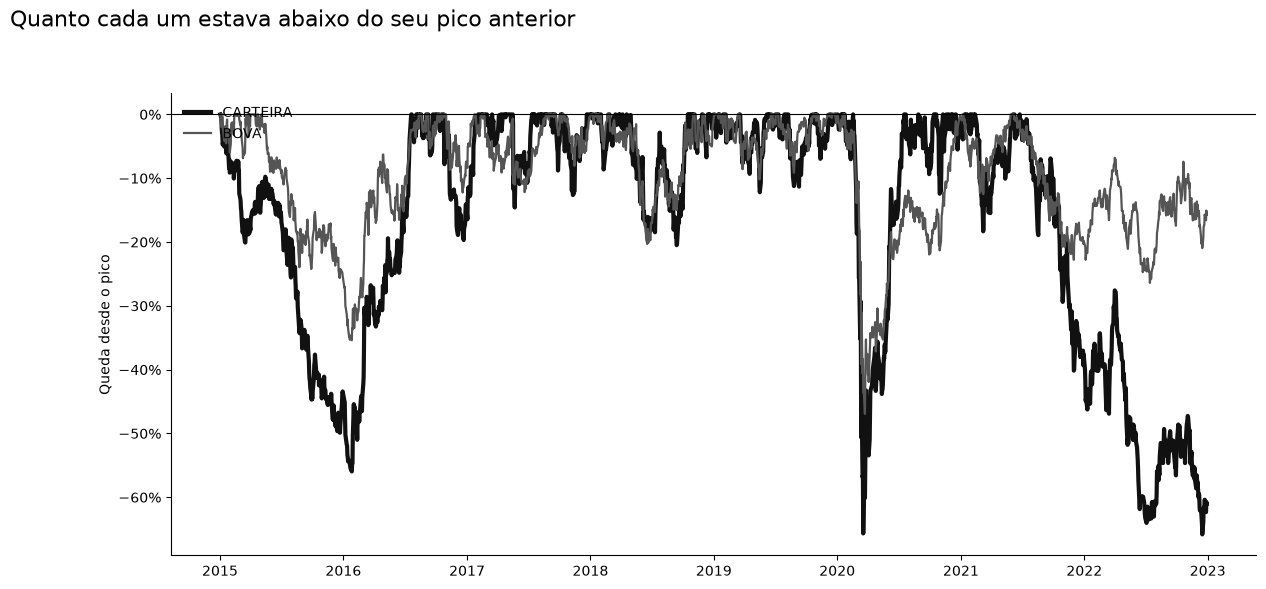

In [23]:
carteira = valor_carteira_pesos_fixos(precos[ACOES], pesos_iguais)   # R$ 1 investido, pesos de 20% mantidos
bova = precos[REFERENCIA] / precos[REFERENCIA].iloc[0]

risco_retorno_carteira = pd.DataFrame({
    nome: {'Volatilidade anual': volatilidade(serie), 'Maior queda': maior_queda(serie), 'CAGR': cagr(serie),
           'Índice de Sharpe': indice_sharpe(serie, cdi), 'R$ 1 virou': serie.iloc[-1]}
    for nome, serie in {'Carteira (20% em cada)': carteira, 'BOVA11': bova, 'CDI': cdi}.items()
}).T
display(risco_retorno_carteira.style.format({'Volatilidade anual': '{:.1%}', 'Maior queda': '{:.1%}', 'CAGR': '{:.1%}',
                                             'Índice de Sharpe': '{:.2f}', 'R$ 1 virou': 'R$ {:.2f}'}))

quedas = pd.DataFrame({'CARTEIRA': carteira / carteira.cummax() - 1, 'BOVA': bova / bova.cummax() - 1})
plot_linhas(quedas, 'Quanto cada um estava abaixo do seu pico anterior', 'Quedas carteira x BOVA',
            ylabel='Queda desde o pico', percentual=True)

**Teste.** Brown-Forsythe entre os retornos diários da carteira e os do BOVA11, com a razão entre os desvios como efeito.

In [24]:
pd.Series(teste_levene(carteira.pct_change().dropna(), bova.pct_change().dropna())).to_frame('H6').T

,teste,estatística,p-valor,efeito,tamanho do efeito
H6,Brown-Forsythe,144.060459,0.0,razão de desvios,1.522202


**Quão certo é esse Sharpe?** Com 8 anos de dados, um Índice de Sharpe varia muito conforme os anos que entram na conta. Medimos essa incerteza com um **bootstrap em blocos**: sorteamos blocos de 21 pregões seguidos (~1 mês), com reposição, até montar 8 anos "alternativos", e recalculamos as medidas 1.000 vezes. Os blocos mantêm juntos os dias agitados, porque a volatilidade vem em ondas.

In [25]:
retornos_bootstrap = pd.DataFrame({'carteira': carteira.pct_change(), 'bova': bova.pct_change(),
                                   'cdi': cdi.pct_change()}).dropna()

def medidas_carteira_bova(amostra):
    sharpe_carteira = indice_sharpe_retornos(amostra['carteira'], amostra['cdi'])
    sharpe_bova = indice_sharpe_retornos(amostra['bova'], amostra['cdi'])
    return {'Volatilidade da carteira': amostra['carteira'].std() * np.sqrt(PREGOES_POR_ANO),
            'Volatilidade do BOVA11': amostra['bova'].std() * np.sqrt(PREGOES_POR_ANO),
            'VaR 95% da carteira': var_historico(amostra['carteira']),
            'Sharpe da carteira': sharpe_carteira, 'Sharpe do BOVA11': sharpe_bova,
            'Sharpe: carteira − BOVA11': sharpe_carteira - sharpe_bova}

intervalos = bootstrap_blocos(retornos_bootstrap, medidas_carteira_bova, n=N_BOOTSTRAP, bloco=BLOCO_BOOTSTRAP,
                              semente=SEMENTE)
intervalos.style.format('{:.3f}')

,estimativa,IC inferior,IC superior
Volatilidade da carteira,0.396,0.331,0.482
Volatilidade do BOVA11,0.260,0.219,0.316
VaR 95% da carteira,0.034,0.031,0.038
Sharpe da carteira,0.245,-0.538,1.374
Sharpe do BOVA11,0.081,-0.560,1.003
Sharpe: carteira − BOVA11,0.164,-0.268,0.790


⚠️ **Parcialmente verdadeira:** o risco maior é certo; a recompensa é provável, mas não comprovada.
- 🔎 **Mais risco:** a carteira oscila **39,6%** ao ano, contra **26,0%** do BOVA11, e chegou a cair **65,8%** do pico ao fundo (BOVA11: **46,9%**). Pelo bootstrap, os intervalos de 95% da volatilidade (**33,1% a 48,2%** na carteira e **21,9% a 31,6%** no BOVA11) **não se encostam**: a diferença de risco é sólida.
- 🔎 **O risco parece ter sido pago:** a carteira cresceu **18,1%** ao ano (R$ 1 → **R$ 3,78**), contra **10,6%** do BOVA11 (R$ 2,24) e **8,6%** do CDI (R$ 1,93). O Índice de Sharpe da carteira é **0,24**, o triplo do BOVA11 (**0,08**).
- ⚠️ **Mas 8 anos não bastam para ter certeza:** o intervalo de 95% do Sharpe vai de **−0,54 a 1,37** na carteira e de **−0,56 a 1,00** no BOVA11. A diferença entre eles (**+0,16**) tem intervalo de **−0,27 a +0,79**, que **inclui o zero**: com outros 8 anos parecidos, o BOVA11 poderia ter ganhado.
- ⚠️ A versão original concluía que "o risco para investir na BOVA é menor" e parava aí. ✅ Na v2, o risco vem acompanhado do retorno (Sharpe) **e** da incerteza dessa comparação.

🧪 **Teste estatístico:** Brown-Forsythe com p < 0,001: os retornos diários da carteira oscilam **1,52 vez** mais que os do BOVA11. Bootstrap em blocos de 21 pregões (1.000 reamostras, semente 42) para os intervalos. O que importa é o tamanho do efeito, não o p.

#### H7 – Quem oscilou mais não rendeu mais

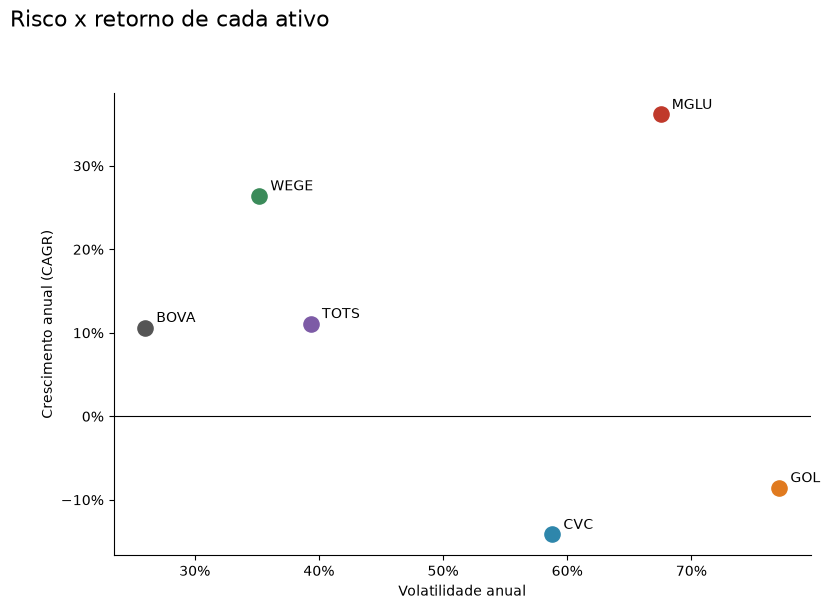

In [26]:
risco_retorno = pd.DataFrame({'Volatilidade anual': volatilidade(precos), 'CAGR': cagr(precos)})

plt.figure(figsize=(9, 6))
for ativo, linha in risco_retorno.iterrows():
    plt.scatter(linha['Volatilidade anual'], linha['CAGR'], s=120, color=CORES[ativo])
    plt.annotate(ativo, (linha['Volatilidade anual'], linha['CAGR']), xytext=(8, 4), textcoords='offset points')
plt.axhline(0, color='black', lw=0.8)
plt.gca().xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
plt.gca().yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
plt.xlabel('Volatilidade anual')
plt.ylabel('Crescimento anual (CAGR)')
sns.despine()
titulo('Risco x retorno de cada ativo')
salvar('Risco x retorno')
plt.show()

**Teste.** Correlação de Spearman entre a volatilidade e o CAGR dos 6 ativos.

In [27]:
pd.Series(teste_spearman(risco_retorno['Volatilidade anual'], risco_retorno['CAGR'])).to_frame('H7').T

,teste,estatística,p-valor,efeito,tamanho do efeito
H7,Spearman,-0.142857,0.787172,rho,-0.142857


✅ **Verdadeira:** mais risco não trouxe mais retorno.
- 🔎 A **GOL** é o ativo mais volátil (**77,1%**) e perdeu dinheiro (**−8,6%** ao ano). A **CVC**, 3ª mais volátil, perdeu **14,2%** ao ano.
- 🔎 A **WEGE**, com volatilidade moderada (**35,2%**), cresceu **26,4%** ao ano e tem o melhor Sharpe do estudo (**0,51**).
- 💡 Risco alto significa **resultados mais extremos**, para cima (MGLU) ou para baixo (GOL, CVC), e não retorno garantido.

🧪 **Teste estatístico:** Spearman de **−0,14** entre volatilidade e CAGR (p = 0,79): não há relação positiva. Com só 6 ativos, o teste tem pouca força.

### 3.4. Resumo das Hipóteses

| # | Hipótese | Resultado | Evidência |
|---|---|---|---|
| H1 | O BOVA11 é o ativo menos volátil | ✅ Verdadeira | 26,0% ao ano, contra 35,2% a 77,1% das ações |
| H2 | O risco disparou na pandemia | ✅ Verdadeira | Movimento diário do BOVA11: 0,87% (2019) → 1,77% (2020) |
| H3 | Os retornos têm caudas gordas | ✅ Verdadeira | Dias além de 3 desvios: 3,9 a 5,8 vezes o esperado |
| H4 | A correlação sobe no estresse | ✅ Verdadeira | 0,25 → 0,51, em 10 de 10 pares |
| H5 | Diversificar reduz o risco | ✅ Verdadeira | 55,6% → 39,6% (razão de diversificação de 1,40) |
| H6 | A carteira é mais arriscada, mas foi recompensada | ⚠️ Em parte | Risco maior com certeza (39,6% x 26,0%); Sharpe maior (0,24 x 0,08), mas o intervalo da diferença inclui o zero |
| H7 | Mais oscilação não rendeu mais | ✅ Verdadeira | Spearman de −0,14; GOL: maior risco e CAGR negativo |

## 4 - FEATURE ENGINEERING — (engenharia de atributos)

| Variável | Fórmula | Para que serve |
|---|---|---|
| **Retorno simples diário** | preço de hoje ÷ preço de ontem − 1 | Base de todas as medidas de risco e da carteira (o retorno da carteira é a média ponderada dos retornos simples) |
| **Retorno logarítmico** | ln(preço final ÷ preço inicial) | Pode ser somado no tempo, mas **não é um percentual de ganho ou perda** |
| **Volatilidade móvel** | desvio dos últimos 63 pregões × √252 | Mostra como o risco muda ao longo do tempo |
| **Queda desde o pico** (*drawdown*) | preço ÷ maior preço anterior − 1 | Quanto o investidor estava perdendo em relação ao melhor momento |

A versão original apresentava o **retorno logarítmico** do período como se fosse a variação percentual do preço:

In [28]:
comparacao_retornos = pd.DataFrame({
    'Retorno log x 100 (v1)': np.log(precos.iloc[-1] / precos.iloc[0]),
    'Variação real do preço (v2)': retorno_total(precos),
    'R$ 1 virou': precos.iloc[-1] / precos.iloc[0],
})
comparacao_retornos.style.format({'Retorno log x 100 (v1)': '{:+.2%}', 'Variação real do preço (v2)': '{:+.1%}',
                                  'R$ 1 virou': 'R$ {:.2f}'})

,Retorno log x 100 (v1),Variação real do preço (v2),R$ 1 virou
GOL,-71.40%,-51.0%,R$ 0.49
CVC,-121.94%,-70.5%,R$ 0.30
WEGE,+187.21%,+550.2%,R$ 6.50
MGLU,+246.55%,+1076.9%,R$ 11.77
TOTS,+84.11%,+131.9%,R$ 2.32
BOVA,+80.73%,+124.2%,R$ 2.24


📌 **Nota: retorno logarítmico não é percentual de ganho ou perda**
- ⚠️ A versão original mostrava a CVC com **−121,94%** e a interpretava como perda de valor. Mas ninguém perde mais de 100% comprando uma ação. A variação real foi de **−70,5%** (R$ 1 virou R$ 0,30).
- 🔎 Nos ganhos, o log **esconde** o tamanho do resultado: a MGLU aparece com +246,55%, mas subiu **+1.076,9%** (R$ 1 → R$ 11,77).
- ✅ Na v2, o retorno do período é a **variação real do preço**, e o crescimento anual é o **CAGR** (da parte 1). O retorno log fica só onde ele é útil: somar retornos ao longo do tempo.

## 5 - EXPLORANDO AS CORRELAÇÕES

Correlação de **Pearson** (relação linear) e de **Spearman** (pelos postos, menos sensível aos dias extremos) dos retornos diários.

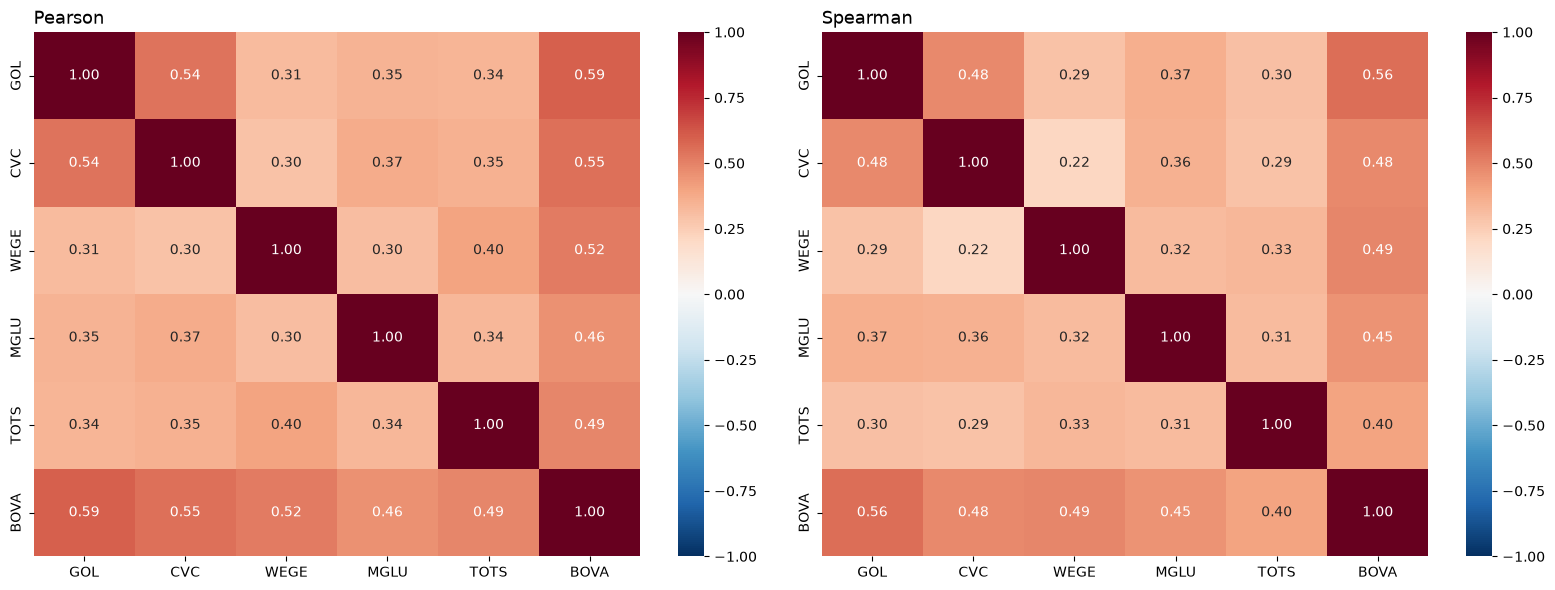

Par MENOS correlacionado: CVC–WEGE (0.296)
Par MAIS correlacionado:  GOL–CVC (0.540)
Correlação média entre as 5 ações: 0.36 | com o BOVA11: 0.46 a 0.59


In [29]:
correlacao = retornos.corr()
correlacao_spearman = retornos.corr(method='spearman')

fig, axs = plt.subplots(1, 2, figsize=(16, 6))
plot_heatmap(correlacao, 'Pearson', None, ax=axs[0])
plot_heatmap(correlacao_spearman, 'Spearman', None, ax=axs[1])
plt.tight_layout()
salvar('Correlacao dos retornos')
plt.show()

pares_corr = pd.Series({f'{a}–{b}': correlacao.loc[a, b] for a, b in pares}).sort_values()
print(f'Par MENOS correlacionado: {pares_corr.index[0]} ({pares_corr.iloc[0]:.3f})')
print(f'Par MAIS correlacionado:  {pares_corr.index[-1]} ({pares_corr.iloc[-1]:.3f})')
print(f'Correlação média entre as 5 ações: {pares_corr.mean():.2f} | com o BOVA11: {correlacao.loc[ACOES, REFERENCIA].min():.2f} a {correlacao.loc[ACOES, REFERENCIA].max():.2f}')

📌 **Nota**
- 🔎 As correlações entre as 5 ações são **baixas a moderadas** (média de **0,36**). A maior é **GOL–CVC (0,54)**, as duas ligadas a viagens.
- ⚠️ A versão original dizia que a menor correlação era entre MGLU e TOTS. Pela própria saída, o par menos correlacionado é **CVC–WEGE (0,296)**; MGLU–TOTS (0,336) é só o 4º. ✅ Corrigido.
- ⚠️ A versão original também dizia que covariância positiva significa "quando uma ação aumenta a outra também aumenta". Uma correlação de 0,3 indica só uma **tendência fraca** de andarem juntas: em muitos dias uma sobe e a outra cai.
- 🔎 Todas as ações têm correlação de **0,46 a 0,59** com o BOVA11: em parte, elas acompanham o mercado.
- 🔎 Pela correlação de Spearman, os valores ficam um pouco **menores** (até 0,09 a menos): os dias extremos, em que tudo cai junto, puxam a correlação de Pearson para cima. É o mesmo efeito da H4.

# FASE 03: INDICADORES DE RISCO

*(No roteiro de Machine Learning, esta é a fase de Modelagem. Aqui, o "modelo" é a forma de medir o risco de cada ação e da carteira.)*

## 1 - Leitura dos dados

In [30]:
print(f'Preços: {precos.shape} | Retornos diários: {retornos.shape}')
retornos.head()

Preços: (1988, 6) | Retornos diários: (1987, 6)


,GOL,CVC,WEGE,MGLU,TOTS,BOVA
Date,,,,,,
2015-01-05,-0.009340,-0.013158,0.006818,0.018792,-0.030726,-0.019890
2015-01-06,0.024242,-0.013333,-0.014834,-0.013175,-0.062536,0.005613
2015-01-07,-0.043392,-0.008784,-0.011457,0.033380,-0.007070,0.033705
2015-01-08,-0.019244,-0.035447,0.016887,-0.007752,0.023220,0.007477
2015-01-09,-0.015417,-0.010601,-0.004559,-0.033854,-0.010287,-0.020202


## 2 - Valores nulos

O primeiro pregão não tem retorno (não existe "dia anterior"), por isso ele sai ao criar os retornos.

In [31]:
print(f'Nulos nos retornos: {retornos.isnull().sum().sum()}')

Nulos nos retornos: 0


## 3 - Transformação

*(Adaptado: **como levar o risco diário para a escala de um ano**.)*

O desvio padrão cresce com a **raiz** do tempo, e não com o tempo: se os dias são independentes, a variância de um ano é 252 vezes a de um dia, então o desvio é **√252** vezes maior. A versão original testou três formas:

In [32]:
desvio_diario = retornos.std()
anualizacao = pd.DataFrame({
    'Desvio diário': desvio_diario,
    'x 246 (v1, errado)': desvio_diario * 246,
    'x raiz de 246 (v1)': desvio_diario * np.sqrt(246),
    'x raiz de 252 (v2)': desvio_diario * np.sqrt(PREGOES_POR_ANO),
})
anualizacao.style.format('{:.2%}')

,Desvio diário,"x 246 (v1, errado)",x raiz de 246 (v1),x raiz de 252 (v2)
GOL,4.86%,1194.59%,76.16%,77.09%
CVC,3.70%,911.28%,58.10%,58.81%
WEGE,2.22%,545.52%,34.78%,35.20%
MGLU,4.25%,1046.51%,66.72%,67.53%
TOTS,2.48%,609.95%,38.89%,39.36%
BOVA,1.64%,403.18%,25.71%,26.02%


📌 **Nota**
- ⚠️ A versão original leu o desvio diário de **4,86%** como "a GOL varia 4 reais e 85 centavos" e depois o multiplicou por **246**. Os dois estão errados: o desvio é dos **retornos** (em %), não do preço (em R$), e o risco cresce com a **raiz** do tempo. Multiplicar por 246 daria uma volatilidade de **1.194,59%** ao ano.
- 🔎 Em seguida, a v1 usou √246 (GOL: **76,16%**), que está certo no método.
- ✅ Na v2 usamos √252 (GOL: **77,09%**). A diferença é de só **1,2%** em todos os ativos (√(252/246)), e os números ficam comparáveis com a parte 1 e com o mercado.

## 4 - Pré-Processamento

### 4.1. Separação do conjunto de dados

Medir o risco do passado não precisa de separação. Mas o **VaR** é usado como **previsão** ("amanhã, a perda não deve passar de X"), e toda previsão precisa ser testada em dados que ela não viu. Separamos então o período em duas partes, **em ordem cronológica** (nunca embaralhar uma série temporal):

| Parte | Período | Uso |
|---|---|---|
| **Estimação** | 2015–2019 | Calcular o VaR "de 2019" e comparar com o que aconteceu depois |
| **Teste** | 2020–2022 | Conferir as previsões, incluindo o choque da pandemia |

In [33]:
estimacao = retornos.loc[:FIM_ESTIMACAO]
teste = retornos.loc[retornos.index > FIM_ESTIMACAO]

pd.DataFrame({'Pregões': [len(estimacao), len(teste)],
              'Início': [estimacao.index[0].date(), teste.index[0].date()],
              'Fim': [estimacao.index[-1].date(), teste.index[-1].date()],
              '% do total': [len(estimacao) / len(retornos), len(teste) / len(retornos)]},
             index=['Estimação', 'Teste']).style.format({'% do total': '{:.0%}'})

,Pregões,Início,Fim,% do total
Estimação,1242,2015-01-05,2019-12-30,63%
Teste,745,2020-01-02,2022-12-29,37%


### 4.2. Balancear os dados

> 🚫 **Não se aplica.** Não há classes a balancear.

### 4.3. Seleção de Variáveis

> 🚫 **Seleção por Random Forest e Informação Mútua: não se aplica.** Esses métodos medem o quanto cada variável ajuda a prever uma **variável-alvo**. Aqui não há alvo nem modelo; a "seleção" é a escolha das **medidas de risco**, cada uma respondendo a uma pergunta diferente do investidor:

| Medida | Pergunta que responde | Na v1? |
|---|---|---|
| **Volatilidade** | Quanto o preço oscila num ano típico? | ✅ (√246) |
| **Semivolatilidade** | E contando só as quedas? | ❌ |
| **Maior queda** | Qual foi o pior momento, do pico ao fundo? | ❌ |
| **VaR 95%** | Num dia ruim (1 em 20), quanto se perde? | ❌ |
| **CVaR 95%** | E quando passa do VaR, quanto se perde em média? | ❌ |
| **Beta** | Quanto a ação amplifica os movimentos do mercado? | ❌ |
| **Índice de Sharpe** | O risco foi pago com retorno acima da renda fixa? | ❌ |
| Desvio dos retornos anuais | Quanto o retorno variou de um ano para o outro? | ✅ (complemento) |
| Coeficiente de variação | — | ✅ (removido na v2, ver item 5) |

## 5 - Treinamento dos Algoritmos de Machine Learning

*(Adaptado: **cálculo de cada medida de risco**.)*

### Volatilidade e semivolatilidade

In [34]:
oscilacao = pd.DataFrame({
    'Volatilidade anual': volatilidade(precos),
    'Semivolatilidade (só quedas)': semivolatilidade(retornos),
})
oscilacao['Parte que vem das quedas'] = oscilacao['Semivolatilidade (só quedas)'] / oscilacao['Volatilidade anual']
oscilacao.sort_values('Volatilidade anual', ascending=False).style.format('{:.1%}')

,Volatilidade anual,Semivolatilidade (só quedas),Parte que vem das quedas
GOL,77.1%,49.2%,63.9%
MGLU,67.5%,42.6%,63.1%
CVC,58.8%,41.1%,69.9%
TOTS,39.4%,27.3%,69.2%
WEGE,35.2%,23.7%,67.3%
BOVA,26.0%,18.7%,71.9%


📌 **Nota**
- 🔎 Do mais ao menos arriscado: **GOL (77,1%) > MGLU (67,5%) > CVC (58,8%) > TOTS (39,4%) > WEGE (35,2%) > BOVA11 (26,0%)**. A semivolatilidade (só as quedas) mantém a mesma ordem.
- 🔎 Se altas e quedas fossem simétricas, a semivolatilidade seria **~71%** da volatilidade. BOVA11 (**71,9%**) e CVC (**69,9%**) ficam perto disso. GOL (**63,9%**) e MGLU (**63,1%**) ficam abaixo: parte da oscilação delas vem de dias de **alta** muito forte (GOL +50,3% em 01/02/2016, MGLU +37,3% em 28/12/2015).
- ✅ **Decisão:** a volatilidade continua como medida principal (a ordem de risco não muda), com a semivolatilidade como conferência.

### Maior queda (*drawdown*)

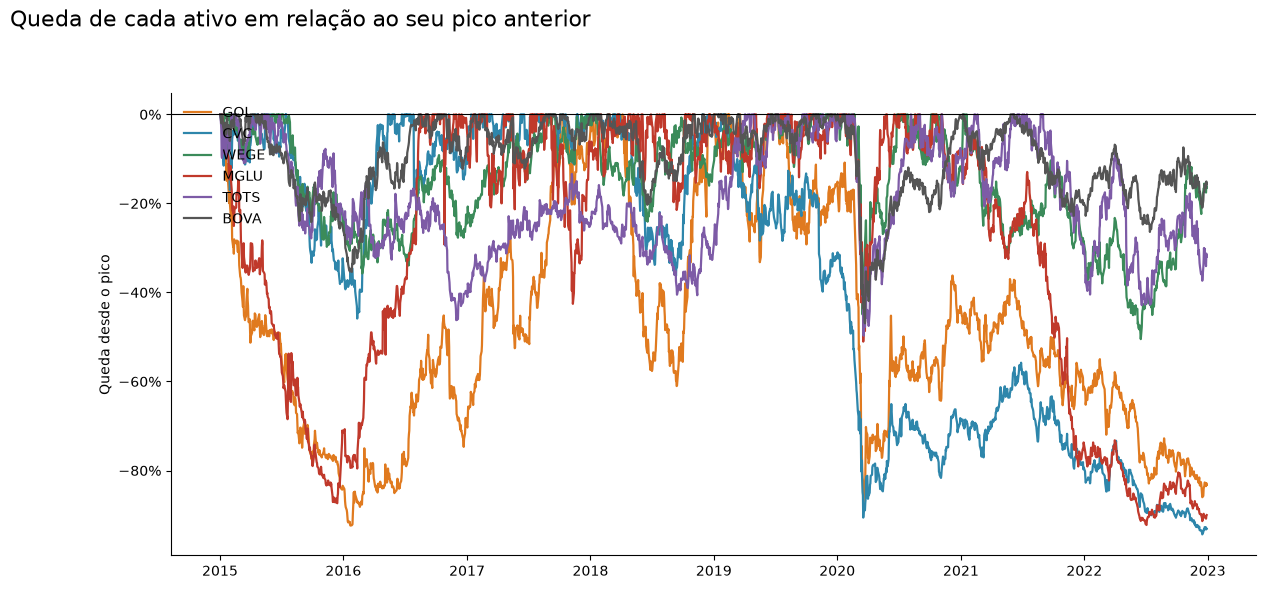

,Maior queda,Data do fundo,Abaixo do pico no fim de 2022
CVC,-94.4%,16/12/2022,-93.1%
GOL,-92.4%,22/01/2016,-83.2%
MGLU,-92.2%,04/07/2022,-90.0%
WEGE,-50.5%,17/06/2022,-16.5%
TOTS,-49.7%,19/03/2020,-32.0%
BOVA,-46.9%,23/03/2020,-15.7%


In [35]:
queda_desde_pico = precos / precos.cummax() - 1
plot_linhas(queda_desde_pico, 'Queda de cada ativo em relação ao seu pico anterior', 'Quedas desde o pico',
            ylabel='Queda desde o pico', percentual=True)

pd.DataFrame({
    'Maior queda': maior_queda(precos),
    'Data do fundo': queda_desde_pico.idxmin().dt.strftime('%d/%m/%Y'),
    'Abaixo do pico no fim de 2022': queda_desde_pico.iloc[-1],
}).sort_values('Maior queda').style.format({'Maior queda': '{:.1%}', 'Abaixo do pico no fim de 2022': '{:.1%}'})

📌 **Nota**
- 🔎 CVC, GOL e MGLU chegaram a perder **mais de 92%** do valor do pico ao fundo: CVC **−94,4%**, GOL **−92,4%** e MGLU **−92,2%**.
- 🔎 No fim de 2022, as três ainda estavam de **83% a 93% abaixo** do pico. A CVC fez o fundo em **16/12/2022**, quase no último pregão da série.
- 🔎 WEGE, TOTS e BOVA11 caíram **cerca de metade** no pior momento (de −46,9% a −50,5%) e se recuperaram em boa parte: o BOVA11 terminou só **15,7%** abaixo do pico.
- 💡 A maior queda é a medida que o investidor **sente**. Para se recuperar de uma queda de 92%, a ação precisa multiplicar o preço por **cerca de 13**.

### VaR e CVaR

- **VaR 95%** (*Value at Risk*): a perda de um dia que só é superada em **1 de cada 20 pregões**.
- **CVaR 95%** (*Expected Shortfall*): a perda **média** nesses dias piores que o VaR. Responde "quando dá errado, quanto dói".

In [36]:
perdas = pd.DataFrame({
    'VaR 95% (1 dia)': var_historico(retornos),
    'CVaR 95% (1 dia)': cvar(retornos),
})
perdas['VaR em R$ 10 mil'] = perdas['VaR 95% (1 dia)'] * 10_000
perdas['CVaR em R$ 10 mil'] = perdas['CVaR 95% (1 dia)'] * 10_000
perdas.sort_values('VaR 95% (1 dia)', ascending=False).style.format(
    {'VaR 95% (1 dia)': '{:.2%}', 'CVaR 95% (1 dia)': '{:.2%}', 'VaR em R$ 10 mil': 'R$ {:,.0f}', 'CVaR em R$ 10 mil': 'R$ {:,.0f}'})

,VaR 95% (1 dia),CVaR 95% (1 dia),VaR em R$ 10 mil,CVaR em R$ 10 mil
GOL,6.44%,9.78%,R$ 644,R$ 978
MGLU,5.75%,8.77%,R$ 575,R$ 877
CVC,5.04%,8.26%,R$ 504,R$ 826
TOTS,3.60%,5.51%,R$ 360,R$ 551
WEGE,3.21%,4.58%,R$ 321,R$ 458
BOVA,2.35%,3.67%,R$ 235,R$ 367


📌 **Nota: quanto se perde num dia ruim**
- 🔎 Com **R$ 10.000** na GOL, em 1 de cada 20 pregões a perda passou de **R$ 644**; nesses dias, a perda média foi de **R$ 978** (CVaR).
- 🔎 No BOVA11, os mesmos números são **R$ 235** e **R$ 367**, quase três vezes menos.
- 🔎 O CVaR é de **43% a 64%** maior que o VaR: quando o dia ruim chega, ele costuma ser bem pior que o limite.
- ✅ **Decisão:** apresentar sempre VaR **e** CVaR. O VaR diz "com que frequência", e o CVaR diz "quanto dói".

### VaR de 10 dias e de 99%

Bancos e reguladores costumam olhar a perda em **10 pregões** (o tempo para conseguir sair de uma posição) e a **99%** (1 dia ruim em cada 100). O atalho comum é a **regra da raiz do tempo**: VaR de 10 dias = VaR de 1 dia × √10. Ela supõe dias independentes e com a mesma oscilação. Comparamos com as perdas acumuladas que **realmente aconteceram** em todas as janelas de 10 pregões seguidos.

In [37]:
retornos_com_carteira = retornos.assign(CARTEIRA=retorno_carteira_pesos_fixos(retornos[ACOES], pesos_iguais))

horizonte = pd.concat({f'{nivel:.0%}': var_horizonte(retornos_com_carteira, 10, nivel) for nivel in (0.95, 0.99)}, axis=1)
for nivel in ('95%', '99%'):
    horizonte[(nivel, 'Erro da raiz do tempo')] = horizonte[(nivel, 'Raiz do tempo')] / horizonte[(nivel, 'Observado')] - 1
horizonte = horizonte.sort_index(axis=1, level=0, sort_remaining=False)
horizonte.style.format('{:.1%}').format('{:+.0%}', subset=[(n, 'Erro da raiz do tempo') for n in ('95%', '99%')])

📌 **Nota: a regra da raiz do tempo funciona?**
- 🔎 **Funciona de forma aproximada.** No VaR de 10 dias a 95%, o erro da regra vai de **−6%** (CVC) a **+15%** (WEGE). Na carteira, a regra dá **10,8%**, contra **11,3%** observados (**−4%**, ou seja, subestima um pouco).
- 🔎 Nos ativos mais calmos (BOVA11 **+14%**, WEGE **+15%**), a regra **exagera** a perda: depois de uma queda, costuma vir uma recuperação parcial. Nos mais voláteis e na carteira, ela **subestima** a 95% (GOL **−3%**, CVC **−6%**, MGLU **−5%**): nas crises, as quedas vêm em sequência.
- 🔎 A 99%, a regra exagera em quase todos (MGLU **+21%**), mas ainda subestima a carteira (**19,3%** x **19,9%**).
- 🔎 **Em reais:** com R$ 10.000 na carteira, a perda de 10 pregões que só foi superada em 1 de cada 20 janelas é de **R$ 1.132**; em 1 de cada 100, de **R$ 1.991**.
- ⚠️ As janelas de 10 dias se sobrepõem: em 8 anos, há só ~198 períodos de 10 dias independentes, então o quantil de 99% depende de **poucos episódios**.
- ✅ **Decisão:** para a carteira, usar o VaR de 10 dias **observado** (um pouco maior que o da regra), e não só a raiz do tempo.

### Beta

O **beta** mede quanto a ação costuma variar quando o mercado (BOVA11) varia 1%. Beta 1,5 = amplifica o mercado em 50%; beta 0,7 = suaviza.

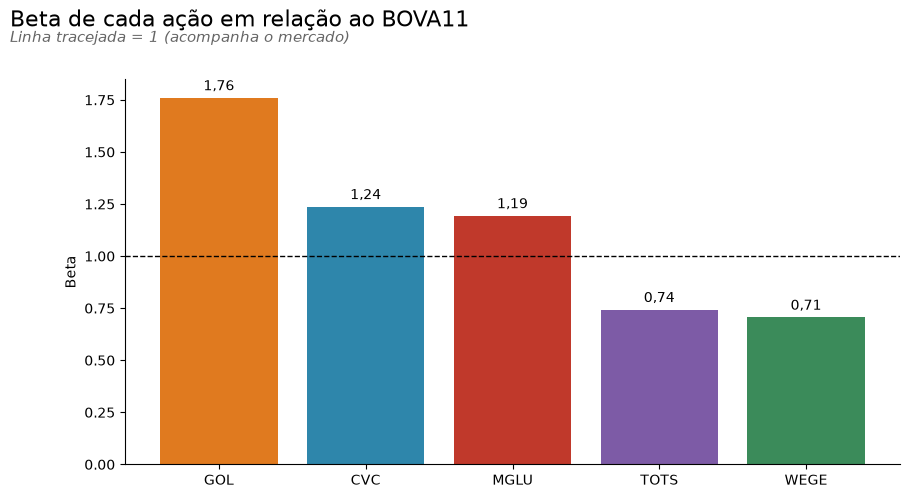

In [38]:
betas = beta(retornos[ACOES], retornos[REFERENCIA]).sort_values(ascending=False)
plot_barras(betas, 'Beta de cada ação em relação ao BOVA11', 'Beta por acao', ylabel='Beta',
            formato='{:.2f}', referencia=1, subtitulo='Linha tracejada = 1 (acompanha o mercado)')

📌 **Nota**
- 🔎 A **GOL** tem beta de **1,76**: quando o mercado cai 1%, ela tende a cair 1,76%. **CVC (1,24)** e **MGLU (1,19)** também amplificam o mercado.
- 🔎 **WEGE (0,71)** e **TOTS (0,74)** suavizam os movimentos do mercado: foram ações mais "defensivas" no período.
- 💡 Beta e volatilidade medem coisas diferentes. A MGLU é muito volátil (67,5%), mas tem beta de só 1,19, porque boa parte da oscilação dela vem de fatores **da própria empresa**, e não do mercado. É justamente esse risco próprio que a diversificação reduz.

### O "risco" da versão original: desvio dos retornos anuais e coeficiente de variação

A versão original calculava o retorno de cada ano (em log, do **primeiro ao último pregão do mesmo ano**), tirava o desvio padrão desses **8 números** e dividia pela média (coeficiente de variação).

In [39]:
# v1: log do 1º ao último pregão de cada ano (perde a virada de um ano para o outro)
retorno_ano_v1 = precos.groupby(precos.index.year).apply(lambda ano: np.log(ano.iloc[-1] / ano.iloc[0]))
# v2: retorno simples do fim do ano anterior ao fim do ano
retorno_ano_v2 = retorno_por_ano(precos)

risco_v1 = pd.DataFrame({
    'Desvio dos retornos anuais (v1)': retorno_ano_v1.std(),
    'Coef. de variação (v1)': pd.Series(stats.variation(retorno_ano_v1), index=retorno_ano_v1.columns),
    'Desvio dos retornos anuais (v2)': retorno_ano_v2.std(),
    'Volatilidade diária anualizada (v2)': volatilidade(precos),
})
risco_v1.style.format('{:.1%}')

,Desvio dos retornos anuais (v1),Coef. de variação (v1),Desvio dos retornos anuais (v2),Volatilidade diária anualizada (v2)
GOL,94.7%,-1087.4%,98.2%,77.1%
CVC,63.8%,-433.9%,61.8%,58.8%
WEGE,34.9%,138.6%,50.7%,35.2%
MGLU,127.1%,379.8%,237.6%,67.5%
TOTS,33.3%,306.0%,51.9%,39.4%
BOVA,17.3%,167.3%,19.0%,26.0%


📌 **Nota: por que a v2 troca o "risco" da versão original**
- ⚠️ **Só 8 números:** a v1 tirava o desvio padrão de 8 retornos anuais. Com tão poucos pontos, a medida é instável: trocando só a forma de calcular o retorno de cada ano (simples e do fim do ano anterior ao fim do ano), o desvio da MGLU passa de **127,1%** para **237,6%**, e o da WEGE de **34,9%** para **50,7%**. A v1 ainda afirmava que "a taxa de retorno da MGLU neste período é de 127%", confundindo desvio com retorno.
- ⚠️ **Coeficiente de variação com média negativa:** a GOL aparece com **−1.087,4%** e a CVC com **−433,9%**. Dividir o desvio por uma média negativa (ou perto de zero) não tem interpretação: um número "menor" não significa menos risco.
- ⚠️ **Log lido como percentual de novo:** a v1 dizia que, comprando no início de 2015, haveria "prejuízo de −121% na MGLU". A queda real da MGLU em 2015 foi de **70,4%**.
- ✅ Na v2, a medida principal é a **volatilidade dos retornos diários** (1.987 observações), e a relação risco × retorno é medida pelo **Índice de Sharpe**. O desvio dos retornos anuais fica só como complemento.

### Validação cruzada

*(Adaptado: **estabilidade ano a ano**.)* No roteiro de modelos, a validação cruzada mostra se o resultado se repete em vários pedaços dos dados (média ± desvio). Aqui fazemos o mesmo com a volatilidade: o ranking de risco se repete em **cada um dos 8 anos**?

In [40]:
vol_por_ano = retornos.groupby(retornos.index.year).std() * np.sqrt(PREGOES_POR_ANO)
display(vol_por_ano.style.format('{:.0%}').background_gradient(cmap='Reds', axis=1))

estabilidade = pd.DataFrame({
    'Média': vol_por_ano.mean(),
    'Desvio entre os anos': vol_por_ano.std(),
    'Anos como o MAIS volátil': vol_por_ano.idxmax(axis=1).value_counts().reindex(precos.columns, fill_value=0),
    'Anos como o MENOS volátil': vol_por_ano.idxmin(axis=1).value_counts().reindex(precos.columns, fill_value=0),
})
estabilidade.sort_values('Média', ascending=False).style.format({'Média': '{:.1%}', 'Desvio entre os anos': '{:.1%}'})

,GOL,CVC,WEGE,MGLU,TOTS,BOVA
Date,,,,,,
2015,57%,36%,28%,82%,38%,24%
2016,118%,39%,33%,74%,35%,27%
2017,57%,29%,26%,70%,27%,20%
2018,66%,40%,28%,48%,31%,23%
2019,48%,39%,26%,41%,31%,18%
2020,112%,108%,58%,70%,60%,44%
2021,54%,59%,35%,57%,39%,21%
2022,70%,76%,37%,83%,45%,22%


,Média,Desvio entre os anos,Anos como o MAIS volátil,Anos como o MENOS volátil
GOL,72.7%,27.0%,4,0
MGLU,65.6%,15.5%,3,0
CVC,53.2%,26.9%,1,0
TOTS,38.2%,10.4%,0,0
WEGE,33.8%,10.6%,0,0
BOVA,24.9%,8.2%,0,8


📌 **Nota: o ranking de risco se repete ano a ano?**
- 🔎 O **BOVA11** foi o ativo menos volátil em **8 de 8 anos**, com média de **24,9% ± 8,2%**.
- 🔎 A **GOL** foi a mais volátil em **4 anos**, a **MGLU** em **3** e a **CVC** em **1** (2021). A CVC, que oscilava de **29% a 40%** até 2019, passou de **108%** em 2020 e ainda estava em **76%** em 2022.
- 🔎 Em **2020**, todos os ativos tiveram uma das maiores volatilidades do período: o BOVA11 foi a **44%**, quase o dobro da sua média.
- 💡 O "desvio entre os anos" mostra que o risco **muda muito no tempo** (de 18% a 44% no BOVA11). Uma volatilidade calculada em anos calmos subestima o risco de uma crise; é o que o backtest do item 8 mede.

## 6 - Comparação do desempenho dos modelos

*(Adaptado: **painel de risco de todos os ativos e da carteira**.)* O **ranking médio** ordena os ativos do menos arriscado (1) ao mais arriscado, na média das 5 medidas de risco.

In [41]:
retornos_carteira = carteira.pct_change().dropna()

painel = pd.DataFrame({
    'Volatilidade anual': volatilidade(precos),
    'Semivolatilidade': semivolatilidade(retornos),
    'Maior queda': maior_queda(precos),
    'VaR 95%': var_historico(retornos),
    'CVaR 95%': cvar(retornos),
    'Beta': beta(retornos, retornos[REFERENCIA]),
    'CAGR': cagr(precos),
    'Índice de Sharpe': indice_sharpe(precos, cdi),
})
painel.loc['CARTEIRA'] = [volatilidade(carteira), semivolatilidade(retornos_carteira), maior_queda(carteira),
                          var_historico(retornos_carteira), cvar(retornos_carteira),
                          beta(retornos_carteira, retornos[REFERENCIA]), cagr(carteira), indice_sharpe(carteira, cdi)]

medidas_risco = ['Volatilidade anual', 'Semivolatilidade', 'VaR 95%', 'CVaR 95%']
painel['Ranking médio de risco'] = pd.concat([painel[medidas_risco].rank(), (-painel['Maior queda']).rank()], axis=1).mean(axis=1)
painel = painel.sort_values('Ranking médio de risco')

PASTA_REPORTS.mkdir(exist_ok=True)
painel.round(4).to_csv(PASTA_REPORTS / 'indicadores_risco.csv', index_label='Ativo')

painel.style.format('{:.1%}', subset=['Volatilidade anual', 'Semivolatilidade', 'Maior queda', 'VaR 95%', 'CVaR 95%', 'CAGR']) \
    .format('{:.2f}', subset=['Beta', 'Índice de Sharpe']).format('{:.1f}', subset=['Ranking médio de risco']) \
    .background_gradient(cmap='Reds', subset=['Ranking médio de risco'])

,Volatilidade anual,Semivolatilidade,Maior queda,VaR 95%,CVaR 95%,Beta,CAGR,Índice de Sharpe,Ranking médio de risco
BOVA,26.0%,18.7%,-46.9%,2.4%,3.7%,1.00,10.6%,0.08,1.0
WEGE,35.2%,23.7%,-50.5%,3.2%,4.6%,0.71,26.4%,0.51,2.2
TOTS,39.4%,27.3%,-49.7%,3.6%,5.5%,0.74,11.1%,0.06,3.0
CARTEIRA,39.6%,28.1%,-65.8%,3.4%,5.5%,1.13,18.1%,0.24,3.8
CVC,58.8%,41.1%,-94.4%,5.0%,8.3%,1.24,-14.2%,-0.39,5.4
MGLU,67.5%,42.6%,-92.2%,5.7%,8.8%,1.19,36.2%,0.41,5.8
GOL,77.1%,49.2%,-92.4%,6.4%,9.8%,1.76,-8.6%,-0.22,6.8


📌 **Nota: painel de risco** (salvo em `reports/indicadores_risco.csv`)
- 🔎 Do menos ao mais arriscado, pelo ranking médio: **BOVA11 → WEGE → TOTS → CARTEIRA → CVC → MGLU → GOL**.
- 🔎 A **carteira** fica no meio: oscila quase como a TOTS (**39,6%** x 39,4%) e tem VaR menor que o dela (**3,4%** x 3,6%). Mas a maior queda (**−65,8%**) e o beta (**1,13**) mostram que ela sofre mais nas crises.
- 🔎 No retorno ajustado ao risco, a **WEGE** se destaca: Sharpe de **0,51**, o maior do painel, com o 2º menor risco. GOL (**−0,22**) e CVC (**−0,39**) têm Sharpe negativo: renderam menos que o CDI.

## 7 - AJUSTE FINO DE HIPERPARÂMETROS

*(Adaptado: **os pesos da carteira**.)*

> 🚫 **Busca de pesos ótimos no período inteiro: não se aplica.** Escolher os pesos "ótimos" olhando 2015–2022 e medir o resultado no mesmo período é usar o futuro. Aqui comparamos as carteiras da versão original; a carteira de **mínima variância**, estimada **só com 2015–2019** e testada em 2020–2022, está na simulação da Fase 05.

### 7.1. As carteiras da versão original

In [42]:
cov_total = covariancia_anual(retornos)
carteiras_v1 = {
    'GOL + CVC (50% cada)': {'GOL': 0.5, 'CVC': 0.5},
    '5 ações (20% cada)': pesos_iguais,
    'BOVA11 (100%)': {REFERENCIA: 1},
}
pd.DataFrame({
    nome: {'Volatilidade v1 (raiz de 246)': np.sqrt(volatilidade_carteira(pesos, cov_total) ** 2 / PREGOES_POR_ANO * 246),
           'Volatilidade v2 (raiz de 252)': volatilidade_carteira(pesos, cov_total),
           'Razão de diversificação': razao_diversificacao(pesos, cov_total)}
    for nome, pesos in carteiras_v1.items()
}).T.style.format({'Volatilidade v1 (raiz de 246)': '{:.1%}', 'Volatilidade v2 (raiz de 252)': '{:.1%}',
                   'Razão de diversificação': '{:.2f}'})

,Volatilidade v1 (raiz de 246),Volatilidade v2 (raiz de 252),Razão de diversificação
GOL + CVC (50% cada),59.1%,59.8%,1.14
5 ações (20% cada),39.1%,39.6%,1.40
BOVA11 (100%),25.7%,26.0%,1.00


📌 **Nota**
- 🔎 Os números da versão original se confirmam com a fórmula w'Σw: **59,1%** para GOL + CVC e **39,1%** para as 5 ações, contra **25,7%** do BOVA11 (com √246). Com √252: **59,8%**, **39,6%** e **26,0%**.
- 🔎 A carteira GOL + CVC quase não se beneficia da diversificação (razão de **1,14**), porque as duas são as ações mais correlacionadas (0,54). Com as 5 ações, a razão sobe para **1,40**.
- 💡 Diversificar é escolher ações que **não** andam juntas. Juntar duas empresas do mesmo setor (viagens) quase não reduz o risco.

### 7.2. Pesos fixos x comprar e manter

A fórmula w'Σw da versão original supõe que a carteira **volta aos 20% todos os dias**. Na prática, quem compra e não mexe deixa os pesos mudarem: a ação que mais sobe passa a dominar a carteira.

In [43]:
comprar_manter = simular_carteira(precos, pesos_iguais, valor_inicial=1)
rebalanceada_ano = simular_carteira(precos, pesos_iguais, valor_inicial=1, rebalancear=True)

estrategias = {'Pesos fixos (todo dia)': carteira, 'Rebalanceada todo ano': rebalanceada_ano,
               'Comprar e manter': comprar_manter, 'BOVA11': bova}
pd.DataFrame({
    nome: {'Volatilidade anual': volatilidade(serie), 'Maior queda': maior_queda(serie), 'CAGR': cagr(serie),
           'Índice de Sharpe': indice_sharpe(serie, cdi)}
    for nome, serie in estrategias.items()
}).T.style.format({'Volatilidade anual': '{:.1%}', 'Maior queda': '{:.1%}', 'CAGR': '{:.1%}', 'Índice de Sharpe': '{:.2f}'})

,Volatilidade anual,Maior queda,CAGR,Índice de Sharpe
Pesos fixos (todo dia),39.6%,-65.8%,18.1%,0.24
Rebalanceada todo ano,37.6%,-62.3%,25.7%,0.46
Comprar e manter,45.5%,-87.2%,19.9%,0.25
BOVA11,26.0%,-46.9%,10.6%,0.08


In [44]:
peso_mglu = (precos['MGLU'] / precos['MGLU'].iloc[0] * 0.2) / comprar_manter
print(f"Comprando e mantendo, a MGLU chegou a {peso_mglu.max():.0%} da carteira em {peso_mglu.idxmax():%m/%Y} (começou com 20%)")

Comprando e mantendo, a MGLU chegou a 91% da carteira em 05/2020 (começou com 20%)


📌 **Nota**
- ⚠️ A fórmula da versão original supõe, sem dizer, que a carteira volta aos 20% **todos os dias**. ✅ Na v2 comparamos com o que o investidor faria de verdade:

| Estratégia | Volatilidade | Maior queda | CAGR | Sharpe |
|---|---|---|---|---|
| Pesos fixos (todo dia) | 39,6% | −65,8% | 18,1% | 0,24 |
| **Rebalanceada todo ano** | **37,6%** | **−62,3%** | **25,7%** | **0,46** |
| Comprar e manter | 45,5% | −87,2% | 19,9% | 0,25 |
| BOVA11 | 26,0% | −46,9% | 10,6% | 0,08 |

- 🔎 **Comprar e manter** é o mais arriscado: a MGLU chegou a **91%** da carteira em **05/2020** (começou com 20%), e a carteira passou a ter o risco de uma ação só.
- 🔎 **Rebalancear todo ano** teve o menor risco entre as carteiras e o melhor Sharpe (**0,46**).
- 💡 O risco de uma carteira depende não só de **quais** ações ela tem, mas também de **manter os pesos**.

### 7.3. Modelo final

A carteira analisada é a da versão original: **20% em cada uma das 5 ações, com os pesos mantidos** (fórmula w'Σw). Ela não usa informação do futuro para escolher os pesos. As versões "comprar e manter" e "rebalanceada todo ano" aparecem como comparação.

## 8 - Otimização de limiar e calibração

*(Adaptado: **o VaR está calibrado?**)* Um VaR de 95% bem calibrado deve ser superado em **~5% dos pregões**. Se for superado muito mais, ele subestima o risco; se muito menos, é conservador demais. O **teste de Kupiec** verifica se a taxa observada é compatível com 5%.

Comparamos duas formas de prever, ambas **só com o passado**, no período de teste (2020–2022):

| VaR | Como é estimado |
|---|---|
| **Fixo de 2019** | Um único número, calculado com 2015–2019 |
| **Móvel** | Recalculado todo dia com os 252 pregões anteriores (último ano) |
| **EWMA filtrado** | Volatilidade de hoje por média móvel exponencial (λ = 0,94: o dia de ontem pesa 6%) x quantil dos retornos padronizados do último ano. Reage a um choque já no dia seguinte e mantém as caudas gordas do histórico |

Além da **taxa** de violações (Kupiec), o **teste de Christoffersen** verifica se elas chegam **isoladas**: violações em sequência mostram um VaR que demora a reagir a uma crise.

In [45]:
estimacao_c = retornos_com_carteira.loc[:FIM_ESTIMACAO]
teste_c = retornos_com_carteira.loc[teste.index]
var_previsto_movel = var_movel(retornos_com_carteira).loc[teste.index]
var_previsto_ewma = var_ewma(retornos_com_carteira, lambda_=LAMBDA_EWMA).loc[teste.index]

linhas = {}
for ativo in retornos_com_carteira:
    fixo = pd.Series(var_historico(estimacao_c[ativo]), index=teste.index)
    linha = {'VaR fixo de 2019': fixo.iloc[0]}
    for nome, previsto in {'fixo': fixo, 'móvel': var_previsto_movel[ativo], 'EWMA': var_previsto_ewma[ativo]}.items():
        violou = violacoes_var(teste_c[ativo], previsto)
        linha[f'Violações ({nome})'] = teste_kupiec(violou)['taxa observada']
        linha[f'p Kupiec ({nome})'] = teste_kupiec(violou)['p-valor']
        if nome != 'fixo':
            linha[f'p independência ({nome})'] = teste_christoffersen(violou)['p-valor (independência)']
    linhas[ativo] = linha

backtest = pd.DataFrame(linhas).T
backtest.style.format('{:.1%}', subset=[c for c in backtest if c.startswith('Violações')]) \
    .format('{:.3f}', subset=[c for c in backtest if c.startswith('p ')]).format('{:.2%}', subset=['VaR fixo de 2019'])

,VaR fixo de 2019,Violações (fixo),p Kupiec (fixo),Violações (móvel),p Kupiec (móvel),p independência (móvel),Violações (EWMA),p Kupiec (EWMA),p independência (EWMA)
GOL,6.03%,6.3%,0.115,6.4%,0.083,0.112,5.9%,0.269,0.154
CVC,3.47%,20.0%,0.000,7.7%,0.002,0.032,5.6%,0.433,0.794
WEGE,2.87%,10.5%,0.000,6.2%,0.155,0.023,5.5%,0.535,0.853
MGLU,5.02%,10.1%,0.000,8.1%,0.000,0.061,6.2%,0.155,0.212
TOTS,3.23%,10.7%,0.000,6.2%,0.155,0.000,5.6%,0.433,0.008
BOVA,2.27%,7.2%,0.008,5.8%,0.345,0.344,5.5%,0.535,0.853
CARTEIRA,2.88%,12.5%,0.000,6.6%,0.059,0.134,6.2%,0.155,0.922


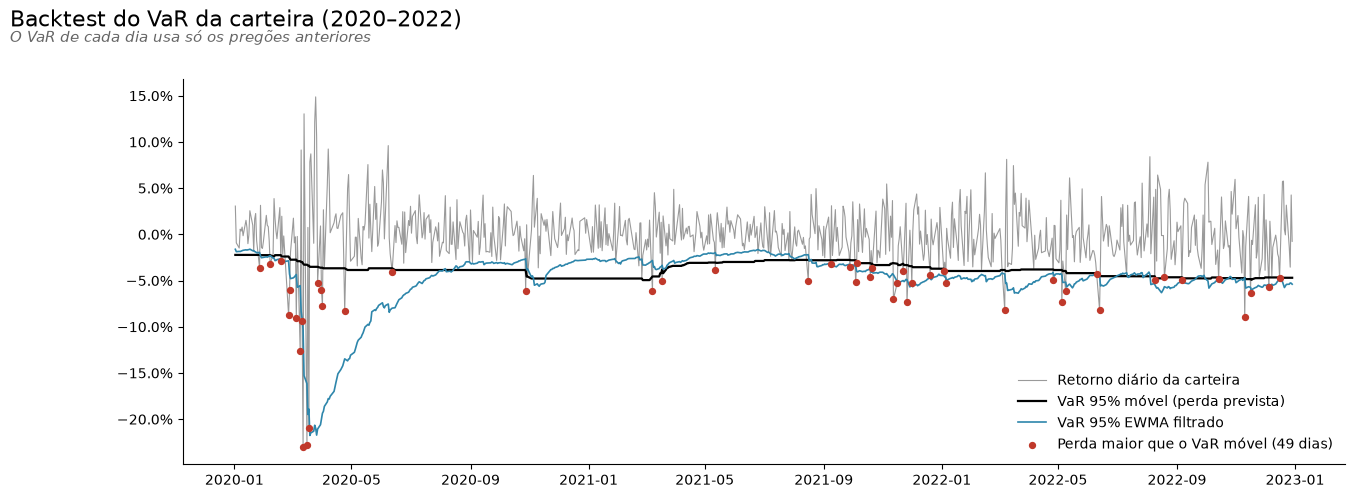

In [46]:
serie = teste_c['CARTEIRA']
previsto = var_previsto_movel['CARTEIRA']
violou = violacoes_var(serie, previsto)

plt.figure(figsize=(15, 5))
plt.plot(serie.index, serie, color='#9A9A9A', lw=0.8, label='Retorno diário da carteira')
plt.plot(previsto.index, -previsto, color='black', lw=1.6, label='VaR 95% móvel (perda prevista)')
plt.plot(var_previsto_ewma.index, -var_previsto_ewma['CARTEIRA'], color=CORES['CVC'], lw=1.2, label='VaR 95% EWMA filtrado')
plt.scatter(serie[violou].index, serie[violou], color=CORES['MGLU'], s=18, zorder=3,
            label=f'Perda maior que o VaR móvel ({violou.sum()} dias)')
plt.gca().yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
plt.legend(frameon=False, loc='lower right')
sns.despine()
titulo('Backtest do VaR da carteira (2020–2022)', 'O VaR de cada dia usa só os pregões anteriores')
salvar('Backtest VaR carteira')
plt.show()

📌 **Nota: o VaR estimado com o passado funcionou na pandemia?**
- ❌ **VaR fixo de 2019:** foi superado em **12,5%** dos pregões da carteira (o esperado era 5%) e em **20,0%** dos pregões da CVC, que em 2019 parecia calma (VaR de 3,47%). O teste de Kupiec rejeita a calibração em **6 dos 7** casos; só a GOL passa (p = 0,115).
- ⚠️ **VaR móvel (último ano):** chega mais perto dos 5%, de **5,8%** (BOVA11) a **8,1%** (MGLU); na carteira, **6,6%**. O Kupiec não rejeita em **5 dos 7** casos, mas o Christoffersen mostra que as violações vêm **em sequência** em CVC, WEGE e TOTS (p < 0,05). No gráfico, **12 das 49** violações da carteira aconteceram em fevereiro e março de 2020: uma janela de 252 pregões demora a "perceber" a crise, porque cada dia novo pesa só 1/252.
- ✅ **VaR EWMA filtrado:** violações de **5,5% a 6,2%** em todos os ativos, e o Kupiec **não rejeita nenhum** dos 7 casos (menor p = 0,155). As violações chegam isoladas em 6 dos 7 (só a TOTS tem p de independência de 0,008). Na carteira, **6,2%** (p de independência = 0,922). No gráfico, a linha do EWMA **desce logo** no início de março de 2020, enquanto a do VaR móvel quase não se mexe.
- ✅ **Decisão:** o **VaR EWMA filtrado** é a estimativa recomendada de "perda para amanhã". Ele reage a um choque já no dia seguinte e mantém as caudas gordas do histórico.

## 9 - Teste anti-vazamento

Reintroduzimos o vazamento de propósito: calculamos o VaR com **a série inteira (2015–2022)**, ou seja, já conhecendo a pandemia, e medimos as violações no mesmo período.

In [47]:
var_com_futuro = var_historico(retornos_com_carteira)
anti_vazamento = pd.DataFrame({
    'Violações com o VaR que vê o futuro': [
        teste_kupiec(violacoes_var(retornos_com_carteira[a], pd.Series(var_com_futuro[a], index=retornos_com_carteira.index)))['taxa observada']
        for a in retornos_com_carteira],
    'Violações com o VaR móvel (só passado, 2020–22)': backtest['Violações (móvel)'].values,
    'Violações com o VaR EWMA (só passado, 2020–22)': backtest['Violações (EWMA)'].values,
    'Violações com o VaR fixo de 2019 (2020–22)': backtest['Violações (fixo)'].values,
}, index=retornos_com_carteira.columns)
anti_vazamento.style.format('{:.1%}')

,Violações com o VaR que vê o futuro,"Violações com o VaR móvel (só passado, 2020–22)","Violações com o VaR EWMA (só passado, 2020–22)",Violações com o VaR fixo de 2019 (2020–22)
GOL,5.0%,6.4%,5.9%,6.3%
CVC,5.0%,7.7%,5.6%,20.0%
WEGE,5.0%,6.2%,5.5%,10.5%
MGLU,5.0%,8.1%,6.2%,10.1%
TOTS,5.0%,6.2%,5.6%,10.7%
BOVA,5.0%,5.8%,5.5%,7.2%
CARTEIRA,5.0%,6.6%,6.2%,12.5%


📌 **Nota**
- 🔎 Com o VaR que **conhece o futuro**, todos os ativos têm exatamente **5,0%** de violações: a calibração parece perfeita. Não é mérito: o VaR histórico de 95% é, por definição, o número que separa os 5% piores dias **da própria amostra**.
- 🔎 Sem o futuro, as violações sobem para **5,5% a 6,2%** com o VaR EWMA, **5,8% a 8,1%** com o VaR móvel e **6,3% a 20,0%** com o VaR fixo de 2019.
- 💡 É o equivalente, em risco, a avaliar um modelo nos próprios dados de treino: o resultado bonito é ilusão.

### 🛡️ Resumo: houve vazamento? Foi resolvido?

- ✅ **Havia risco de vazamento?** Sim: calcular o VaR com o período inteiro usa a pandemia para "prever" a pandemia.
- ✅ **Foi resolvido?** Sim. Todo VaR usado como previsão é estimado só com os pregões **anteriores** (`var_movel` e `var_ewma` com `shift(1)`, testados em `tests/test_risco.py`), e o backtest usa só 2020–2022, período que a estimação de 2019 não viu.
- ⚠️ As medidas descritivas do painel (volatilidade, maior queda, VaR histórico) usam o período inteiro **de propósito**: elas **descrevem** o passado, não o **preveem**.

# FASE 04: AVALIAÇÃO

Avaliamos as respostas de risco **em reais** e **fora da amostra**: o que um investidor de R$ 10.000 teria enfrentado, se as previsões de 2019 se confirmaram na pandemia e de onde vem o risco da carteira.

## 1 - Avaliando a Máquina Preditiva

*(Adaptado: **o risco em reais e as conclusões da versão original, revistas**.)*

In [48]:
VALOR = 10_000
em_reais = pd.DataFrame({
    nome: {'Perda num dia ruim (VaR 95%)': var_historico(r) * VALOR,
           'Perda média nos piores dias (CVaR 95%)': cvar(r) * VALOR,
           'Pior dia do período': -r.min() * VALOR,
           'Maior queda do pico ao fundo': -maior_queda((1 + r).cumprod()) * VALOR}
    for nome, r in {'Carteira (20% em cada)': retornos_com_carteira['CARTEIRA'],
                    'BOVA11': retornos[REFERENCIA], 'GOL (a mais arriscada)': retornos['GOL'],
                    'WEGE (a ação menos arriscada)': retornos['WEGE']}.items()
}).T
em_reais.style.format('R$ {:,.0f}')

,Perda num dia ruim (VaR 95%),Perda média nos piores dias (CVaR 95%),Pior dia do período,Maior queda do pico ao fundo
Carteira (20% em cada),R$ 343,R$ 552,"R$ 2,300","R$ 6,582"
BOVA11,R$ 235,R$ 367,"R$ 1,457","R$ 4,693"
GOL (a mais arriscada),R$ 644,R$ 978,"R$ 3,629","R$ 9,237"
WEGE (a ação menos arriscada),R$ 321,R$ 458,"R$ 2,062","R$ 5,048"


📌 **Nota: o risco em reais, para R$ 10.000 investidos**

| | Dia ruim (VaR 95%) | Média dos piores dias (CVaR) | Pior dia | Maior queda do pico ao fundo |
|---|---|---|---|---|
| **Carteira (20% em cada)** | **R$ 343** | **R$ 552** | **R$ 2.300** | **R$ 6.582** |
| BOVA11 | R$ 235 | R$ 367 | R$ 1.457 | R$ 4.693 |
| GOL | R$ 644 | R$ 978 | R$ 3.629 | R$ 9.237 |
| WEGE | R$ 321 | R$ 458 | R$ 2.062 | R$ 5.048 |

- 🔎 Na carteira, o investidor deve esperar perder **mais de R$ 343** em cerca de **1 pregão a cada 20** (uma vez por mês, em média). No pior momento, a queda foi de **65,8%** do pico ao fundo: R$ 6.582 de cada R$ 10.000 que estivessem aplicados no pico.
- 🔎 Juntar as 5 ações deixou a carteira **menos arriscada que a GOL em todas as medidas** e com VaR próximo ao da WEGE, mas ainda **46% acima do BOVA11** (R$ 343 x R$ 235).

**As conclusões da versão original, revistas:**

| Afirmação da v1 | Na v2 |
|---|---|
| "O risco para investir na BOVA é menor": 0,39 x 0,25 | ✅ Confirmado: 39,6% x 26,0% (√252). Mas a carteira rendeu 18,1% ao ano x 10,6% e tem Sharpe três vezes maior (diferença incerta, H6) |
| "A WEGE apresentou o menor risco médio anual" | ⚠️ O menor entre as **ações**; o BOVA11 é ainda menor |
| "A pior ação é a CVC: maior risco e menor retorno" | ⚠️ A CVC tem o menor retorno (−14,2% ao ano), mas o maior risco é o da GOL (77,1%). As duas têm Sharpe negativo |
| "A MGLU apresentou o maior retorno" | ✅ CAGR de 36,2% ao ano, com a 2ª maior volatilidade (67,5%) |

### 1.1. Testes de estresse: e se as crises do período se repetissem?

O VaR fala de um dia ruim "comum" (1 em 20). Um **teste de estresse** pergunta outra coisa: quanto a carteira perderia se cada ação repetisse exatamente o que fez numa **crise real**? Usamos quatro choques do período:

In [49]:
estresse_linhas = {}
for nome, (inicio, fim) in CENARIOS_ESTRESSE.items():
    choques = choques_cenario(precos, inicio, fim)
    estresse_linhas[nome] = {**{acao: choques[acao] for acao in ACOES}, 'BOVA11': choques[REFERENCIA],
                             'Carteira em R$ 10 mil': perda_cenario(pesos_iguais, choques, VALOR),
                             'BOVA11 em R$ 10 mil': choques[REFERENCIA] * VALOR}
estresse_tabela = pd.DataFrame(estresse_linhas).T
estresse_tabela['VaR 95% da carteira (1 dia)'] = -var_historico(retornos_com_carteira['CARTEIRA']) * VALOR
estresse_tabela.style.format('{:+.1%}', subset=ACOES + ['BOVA11']) \
    .format('R$ {:+,.0f}', subset=['Carteira em R$ 10 mil', 'BOVA11 em R$ 10 mil', 'VaR 95% da carteira (1 dia)'])

,GOL,CVC,WEGE,MGLU,TOTS,BOVA11,Carteira em R$ 10 mil,BOVA11 em R$ 10 mil,VaR 95% da carteira (1 dia)
Joesley Day (18/05/2017),-20.1%,-9.4%,-2.8%,-16.2%,-4.3%,-8.7%,"R$ -1,056",R$ -866,R$ -343
Greve dos caminhoneiros (mai/2018),-6.5%,+3.5%,-6.8%,+9.9%,-1.8%,-7.0%,R$ -35,R$ -697,R$ -343
Pior dia da pandemia (12/03/2020),-36.3%,-29.1%,-15.8%,-21.1%,-12.7%,-14.6%,"R$ -2,300","R$ -1,457",R$ -343
Queda da pandemia (19/02 a 23/03/2020),-80.9%,-76.7%,-27.9%,-47.8%,-46.8%,-45.4%,"R$ -5,602","R$ -4,545",R$ -343


📌 **Nota: as crises reais, em reais**
- 🔎 **Queda da pandemia (19/02 a 23/03/2020):** a carteira perderia **R$ 5.602** de R$ 10.000, contra **R$ 4.545** no BOVA11. GOL (**−80,9%**) e CVC (**−76,7%**) puxam a perda. São **16 vezes** o VaR de 1 dia (R$ 343).
- 🔎 **Pior dia da pandemia (12/03/2020):** **R$ 2.300** num único pregão, quase **7 vezes** o VaR, contra R$ 1.457 no BOVA11.
- 🔎 **Joesley Day (18/05/2017):** a carteira perde **R$ 1.056**, contra R$ 866 no BOVA11 (GOL −20,1%, MGLU −16,2%).
- 🔎 **Greve dos caminhoneiros (mai/2018):** a carteira perde só **R$ 35**, contra **R$ 697** no BOVA11, porque MGLU (**+9,9%**) e CVC (**+3,5%**) subiram no período e compensaram as quedas.
- 💡 Nas crises que atingem o mercado todo, a carteira perde **mais** que o BOVA11 (beta de 1,13). Num choque que não atinge todas as empresas igualmente, a diversificação entre setores pode proteger.
- ✅ O VaR mede o dia ruim "comum"; o teste de estresse mostra a crise. Os dois aparecem no app.

### 1.2. Extensão até 2025: o risco antes, durante e depois da Covid

A análise principal termina em dez/2022, como a versão original. Aqui estendemos o estudo até **30/12/2025** e comparamos o risco em três fases:

| Fase | Datas | Por quê |
|---|---|---|
| **Pré-pandemia** | 02/01/2015 a 19/02/2020 | Até a véspera da queda da bolsa |
| **Pandemia** | 20/02/2020 a 05/05/2023 | Até o fim da emergência de saúde declarado pela OMS |
| **Pós-pandemia** | 06/05/2023 a 30/12/2025 | Os anos seguintes, que a versão original não conhecia |

Os anos de **2023 a 2025** também são um **teste fora do tempo** do VaR EWMA, o método escolhido com os dados até 2022 (item 8 da Fase 03).

> ⚠️ **A GOL fica de fora da extensão.** Depois da recuperação judicial nos EUA (*Chapter 11*), a ação virou GOLL54, passou a valer menos de R$ 0,01 e está saindo da bolsa. Não há dados públicos gratuitos dela depois de 2022 (o Yahoo Finance não tem mais o ticker). Por isso, a carteira estendida tem **4 ações com 25% em cada** (CVC, WEGE, MGLU e TOTS), com os pesos mantidos todo dia, como na análise principal.

> ℹ️ A base estendida (`acoes_2015_2025.csv`) veio de um download novo do Yahoo Finance, que agora ajusta o preço da CVC pelos aumentos de capital de 2020 a 2022 (a base antiga mostrava esses dias como quedas de até −8%). Por isso, os números da CVC até 2022 diferem um pouco dos da análise principal.

In [50]:
if ATUALIZAR_DADOS:   # o mesmo controle do item 1.2 da Fase 02
    estendida = baixar_precos(TICKERS, fim='2026-01-01', coluna='Close').ffill()
    # GOL: sem dados públicos depois de 2022; mantém o histórico da base original
    estendida['GOLL4.SA'] = pd.read_csv(PASTA_DADOS / 'acoes.csv', parse_dates=['Date'], index_col='Date')['GOLL4.SA']
    estendida.to_csv(PASTA_DADOS / 'acoes_2015_2025.csv')
    baixar_cdi(fim='2025-12-31').to_csv(PASTA_DADOS / 'cdi_2015_2025.csv')

precos_2025 = carregar_precos(PASTA_DADOS / 'acoes_2015_2025.csv')
ACOES_2025 = [a for a in ativos_com_dados(precos_2025) if a != REFERENCIA]
pesos_2025 = {acao: 1 / len(ACOES_2025) for acao in ACOES_2025}
retornos_2025 = retornos_diarios(precos_2025[ACOES_2025 + [REFERENCIA]])
retornos_2025['CARTEIRA'] = retorno_carteira_pesos_fixos(retornos_2025[ACOES_2025], pesos_2025)
fase_2025 = classificar_periodo(retornos_2025.index)

print(f'Pregões: {len(precos_2025)} ({precos_2025.index[0]:%d/%m/%Y} a {precos_2025.index[-1]:%d/%m/%Y})')
print(f"Ações com dados no período todo: {ACOES_2025} | GOL: dados até {precos_2025['GOL'].last_valid_index():%d/%m/%Y}")
print()
print('Pregões por fase:')
print(fase_2025.value_counts().reindex(list(PERIODOS_COVID)).to_string())

Pregões: 2737 (02/01/2015 a 30/12/2025)
Ações com dados no período todo: ['CVC', 'WEGE', 'MGLU', 'TOTS'] | GOL: dados até 29/12/2022

Pregões por fase:
Pré-pandemia    1277
Pandemia         795
Pós-pandemia     664


,Pré-pandemia,Pandemia,Pós-pandemia
Volatilidade CVC,36.8%,85.5%,64.5%
Volatilidade WEGE,28.8%,42.6%,27.9%
Volatilidade MGLU,64.8%,72.0%,67.3%
Volatilidade TOTS,32.8%,47.8%,30.0%
Volatilidade BOVA,22.4%,30.5%,14.8%
Volatilidade CARTEIRA,26.6%,48.1%,34.1%
VaR 95% CARTEIRA,2.5%,4.4%,3.1%
VaR 95% BOVA,2.3%,2.5%,1.4%
Maior queda CARTEIRA,-40.7%,-65.3%,-42.2%
Maior queda BOVA,-35.4%,-44.5%,-13.6%


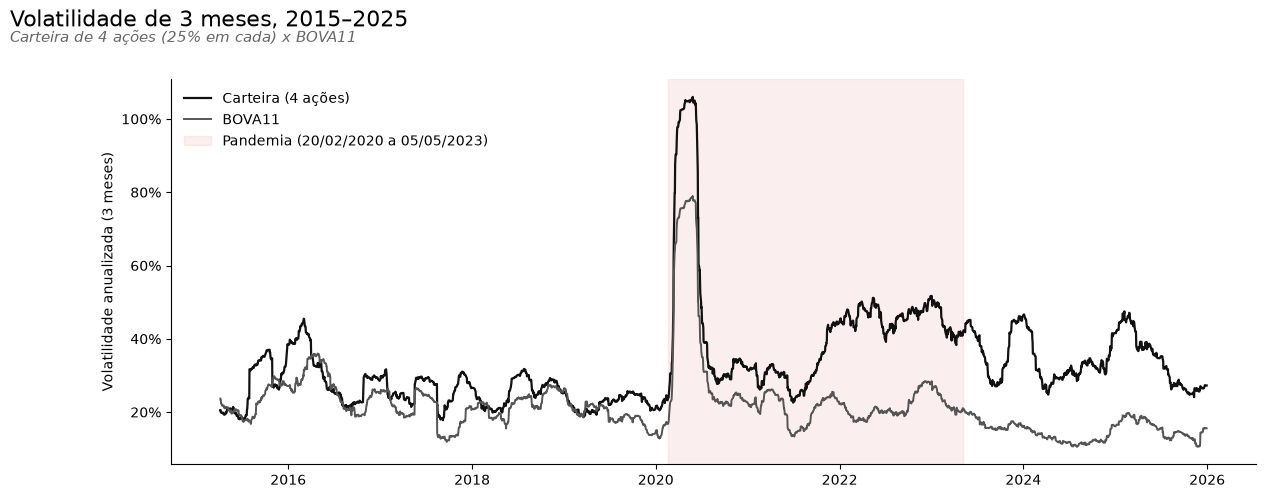

In [51]:
pares_2025 = [(a, b) for i, a in enumerate(ACOES_2025) for b in ACOES_2025[i + 1:]]
risco_fase = {}
for nome in PERIODOS_COVID:
    r = retornos_2025[fase_2025 == nome]
    correlacao_fase = r[ACOES_2025].corr()
    risco_fase[nome] = {**{f'Volatilidade {ativo}': r[ativo].std() * np.sqrt(PREGOES_POR_ANO) for ativo in r},
                        'VaR 95% CARTEIRA': var_historico(r['CARTEIRA']), 'VaR 95% BOVA': var_historico(r[REFERENCIA]),
                        'Maior queda CARTEIRA': maior_queda((1 + r['CARTEIRA']).cumprod()),
                        'Maior queda BOVA': maior_queda((1 + r[REFERENCIA]).cumprod()),
                        'Correlação média entre as ações': np.mean([correlacao_fase.loc[a, b] for a, b in pares_2025]),
                        **{f'Beta {acao}': beta(r[acao], r[REFERENCIA]) for acao in ACOES_2025}}
risco_fase = pd.DataFrame(risco_fase)
linhas_numero = ['Correlação média entre as ações'] + [f'Beta {acao}' for acao in ACOES_2025]
display(risco_fase.style.format('{:.1%}').format('{:.2f}', subset=pd.IndexSlice[linhas_numero, :]))

vol_movel_2025 = volatilidade_movel(retornos_2025[['CARTEIRA', REFERENCIA]]).dropna()
plt.figure(figsize=(14, 5))
plt.plot(vol_movel_2025.index, vol_movel_2025['CARTEIRA'], color=CORES['CARTEIRA'], lw=1.6, label='Carteira (4 ações)')
plt.plot(vol_movel_2025.index, vol_movel_2025[REFERENCIA], color=CORES['BOVA'], lw=1.4, label='BOVA11')
plt.axvspan(pd.Timestamp(PERIODOS_COVID['Pandemia'][0]), pd.Timestamp(PERIODOS_COVID['Pandemia'][1]),
            color='#C0392B', alpha=0.08, label='Pandemia (20/02/2020 a 05/05/2023)')
plt.gca().yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
plt.ylabel('Volatilidade anualizada (3 meses)')
plt.legend(frameon=False, loc='upper left')
sns.despine()
titulo('Volatilidade de 3 meses, 2015–2025', 'Carteira de 4 ações (25% em cada) x BOVA11')
salvar('Volatilidade 2015-2025 Covid')
plt.show()

**Teste.** Kruskal-Wallis do tamanho do movimento diário da carteira (|retorno|) entre as três fases, com épsilon², e Mann-Whitney entre o pós e o pré-pandemia, com a correlação de postos.

In [52]:
movimento_carteira = retornos_2025['CARTEIRA'].abs()
pd.DataFrame({
    'Kruskal (3 fases)': teste_kruskal(movimento_carteira, fase_2025),
    'Mann-Whitney (pós x pré)': teste_mann_whitney(movimento_carteira[fase_2025 == 'Pós-pandemia'],
                                                   movimento_carteira[fase_2025 == 'Pré-pandemia']),
}).T

,teste,estatística,p-valor,efeito,tamanho do efeito
Kruskal (3 fases),Kruskal-Wallis,116.513036,0.0,épsilon²,0.042601
Mann-Whitney (pós x pré),Mann-Whitney,487723.0,0.0,correlação de postos,0.150388


📌 **Nota: o risco antes, durante e depois da Covid**

| | Pré-pandemia | Pandemia | Pós-pandemia |
|---|---|---|---|
| **Volatilidade da carteira (4 ações)** | 26,6% | **48,1%** | **34,1%** |
| **Volatilidade do BOVA11** | 22,4% | 30,5% | **14,8%** |
| **VaR 95% da carteira / BOVA11** | 2,5% / 2,3% | 4,4% / 2,5% | 3,1% / **1,4%** |
| **Maior queda da carteira / BOVA11** | −40,7% / −35,4% | −65,3% / −44,5% | −42,2% / **−13,6%** |
| **Correlação média entre as ações** | 0,20 | **0,45** | 0,26 |

- 🔎 **Na pandemia, tudo ficou mais arriscado:** a volatilidade da carteira quase dobrou (26,6% → 48,1%), e a correlação entre as ações mais que dobrou (0,20 → 0,45), confirmando a H4 com dados até 2025.
- 🔎 **Depois, o mercado acalmou, mas a carteira não:** o BOVA11 teve a **menor** volatilidade das três fases (**14,8%**) e caiu só 13,6% no pior momento. A carteira ficou **mais** arriscada do que antes da Covid (**34,1%** x 26,6%), com maior queda de −42,2%.
- 🔎 O motivo está em duas ações: CVC (**64,5%**, contra 36,8% antes) e MGLU (**67,3%**) continuaram muito voláteis, e o beta delas disparou (**2,17** e **2,60**): no pós-pandemia, elas amplificaram o mercado mais que o dobro. WEGE (27,9%) e TOTS (30,0%) voltaram ao nível de antes.
- 💡 A correlação voltou perto do normal (0,26), mas o risco próprio de CVC e MGLU (empresas endividadas, num período de juros altos) manteve a carteira arriscada.

🧪 **Teste estatístico:** Kruskal-Wallis do tamanho do movimento diário da carteira entre as 3 fases com p < 0,001 e épsilon² de **0,043** (efeito pequeno). Pós x pré: Mann-Whitney com correlação de postos de **+0,15** (efeito pequeno): os movimentos diários da carteira ficaram **maiores** depois da Covid. O que importa é o tamanho do efeito, não o p.

**O VaR EWMA continuou funcionando com dados novos?** Medimos as violações de 2023 a 2025, anos que não existiam quando o método foi escolhido.

In [53]:
depois_2022 = retornos_2025.index > '2022-12-31'
var_ewma_2025 = var_ewma(retornos_2025, lambda_=LAMBDA_EWMA)
var_movel_2025 = var_movel(retornos_2025)

linhas = {}
for ativo in retornos_2025:
    linha = {}
    for nome, previsto in {'EWMA': var_ewma_2025[ativo], 'móvel': var_movel_2025[ativo]}.items():
        violou = violacoes_var(retornos_2025.loc[depois_2022, ativo], previsto[depois_2022])
        linha[f'Violações ({nome})'] = teste_kupiec(violou)['taxa observada']
        linha[f'p Kupiec ({nome})'] = teste_kupiec(violou)['p-valor']
        linha[f'p independência ({nome})'] = teste_christoffersen(violou)['p-valor (independência)']
    linhas[ativo] = linha
backtest_2025 = pd.DataFrame(linhas).T
backtest_2025.style.format('{:.1%}', subset=[c for c in backtest_2025 if c.startswith('Violações')]) \
    .format('{:.3f}', subset=[c for c in backtest_2025 if c.startswith('p ')])

,Violações (EWMA),p Kupiec (EWMA),p independência (EWMA),Violações (móvel),p Kupiec (móvel),p independência (móvel)
CVC,5.2%,0.796,0.193,4.4%,0.447,0.677
WEGE,5.2%,0.796,0.980,4.8%,0.807,0.355
MGLU,5.1%,0.927,0.044,4.4%,0.447,0.677
TOTS,5.1%,0.927,0.462,4.1%,0.266,0.158
BOVA,4.9%,0.940,0.506,4.0%,0.196,0.872
CARTEIRA,5.2%,0.796,0.980,3.9%,0.141,0.410


📌 **Nota: o VaR EWMA passou no teste fora do tempo**
- ✅ Em 2023–2025, anos que não existiam quando o método foi escolhido, o **VaR EWMA filtrado** foi superado em **4,9% a 5,2%** dos pregões, praticamente os 5% esperados. O Kupiec não rejeita em nenhum ativo (menor p = 0,796), e as violações chegam isoladas em 5 dos 6 casos (só a MGLU tem p de independência de 0,044). Na carteira: **5,2%** (p de independência = 0,980).
- 🔎 O **VaR móvel** ficou **conservador demais** num período mais calmo: de **3,9%** (carteira) a 4,8% de violações. A janela de 252 pregões ainda carregava dias agitados e demorou a perceber a calmaria; o Kupiec não o rejeita, mas ele "pede" mais proteção do que o necessário.
- 💡 O EWMA acerta nos dois sentidos: reage rápido quando o risco sobe (pandemia, item 8 da Fase 03) e quando cai (pós-pandemia).

## 2 - Previsto x observado

*(Adaptado: **o risco "previsto" com 2015–2019 x o risco que aconteceu em 2020–2022**.)*

In [54]:
previsto_observado = pd.DataFrame({
    'Volatilidade 2015–19 (prevista)': estimacao_c.std() * np.sqrt(PREGOES_POR_ANO),
    'Volatilidade 2020–22 (observada)': teste_c.std() * np.sqrt(PREGOES_POR_ANO),
    'VaR 95% de 2019 (previsto)': var_historico(estimacao_c),
    'Perda de 1 em 20 dias em 2020–22 (observada)': var_historico(teste_c),
})
previsto_observado['Erro do VaR'] = (previsto_observado['Perda de 1 em 20 dias em 2020–22 (observada)']
                                     / previsto_observado['VaR 95% de 2019 (previsto)'] - 1)
previsto_observado.style.format('{:.1%}', subset=previsto_observado.columns[:2]) \
    .format('{:.2%}', subset=previsto_observado.columns[2:4]).format('{:+.0%}', subset=['Erro do VaR'])

,Volatilidade 2015–19 (prevista),Volatilidade 2020–22 (observada),VaR 95% de 2019 (previsto),Perda de 1 em 20 dias em 2020–22 (observada),Erro do VaR
GOL,73.7%,82.3%,6.03%,6.61%,+9%
CVC,36.7%,83.5%,3.47%,6.97%,+101%
WEGE,28.2%,44.5%,2.87%,3.77%,+31%
MGLU,65.4%,70.7%,5.02%,6.88%,+37%
TOTS,32.6%,48.6%,3.23%,4.60%,+42%
BOVA,22.5%,31.0%,2.27%,2.56%,+13%
CARTEIRA,29.9%,51.8%,2.88%,4.63%,+61%


📌 **Nota**
- 🔎 Quem olhasse só 2015–2019 teria **subestimado** o risco de todos os ativos em 2020–2022: a perda de "1 em cada 20 dias" veio de **9%** (GOL) a **101%** (CVC) maior que o VaR de 2019.
- 🔎 O maior erro foi o da **CVC**: a volatilidade passou de **36,7%** para **83,5%**. A empresa de turismo parecia moderada até a pandemia fechar as viagens.
- 🔎 Na carteira, a volatilidade foi de **29,9%** para **51,8%**, e a perda de 1 em 20 dias ficou **61%** acima da prevista.
- 💡 O risco histórico é um **piso**, não um teto: ele não inclui as crises que ainda não aconteceram. Por isso o VaR deve ser recalculado com frequência (VaR EWMA, Fase 03, item 8) e complementado por cenários de estresse (item 1.1).

## 3 - Quais variáveis mais influenciam o modelo?

*(Adaptado: **de onde vem o risco da carteira**.)* Cada ação pesa 20% no **dinheiro**, mas não necessariamente 20% no **risco**. A contribuição de cada uma depende da sua volatilidade **e** da correlação com as outras.

,Peso no dinheiro,Peso no risco,Peso no risco (2020–22)
GOL,20.0%,30.9%,27.5%
MGLU,20.0%,24.1%,20.8%
CVC,20.0%,22.4%,27.0%
TOTS,20.0%,12.4%,13.8%
WEGE,20.0%,10.2%,10.9%


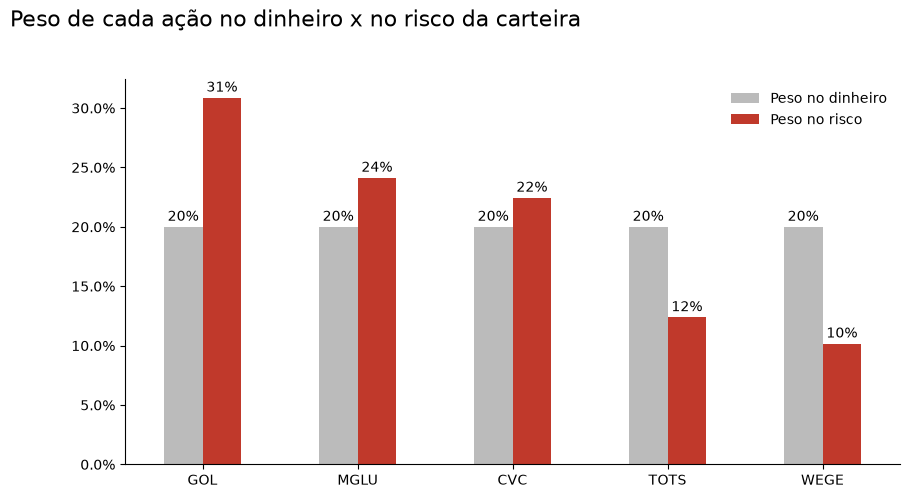

In [55]:
contribuicao = pd.DataFrame({'Peso no dinheiro': pd.Series(pesos_iguais),
                             'Peso no risco': contribuicao_risco(pesos_iguais, cov_acoes)})
contribuicao['Peso no risco (2020–22)'] = contribuicao_risco(pesos_iguais, covariancia_anual(teste[ACOES]))
contribuicao = contribuicao.sort_values('Peso no risco', ascending=False)
display(contribuicao.style.format('{:.1%}'))

ax = contribuicao[['Peso no dinheiro', 'Peso no risco']].plot.bar(figsize=(10, 5), color=['#BBBBBB', '#C0392B'], rot=0)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
for barras in ax.containers:
    ax.bar_label(barras, labels=[f'{v:.0%}' for v in barras.datavalues], padding=2)
ax.legend(frameon=False)
sns.despine()
titulo('Peso de cada ação no dinheiro x no risco da carteira')
salvar('Contribuicao para o risco')
plt.show()

📌 **Nota: cada ação tem 20% do dinheiro, mas não 20% do risco**
- 🔎 A **GOL** responde por **30,9%** do risco da carteira. GOL, MGLU e CVC juntas têm 60% do dinheiro e **77%** do risco.
- 🔎 **WEGE** (10,2%) e **TOTS** (12,4%) têm 40% do dinheiro e só **22,6%** do risco.
- 🔎 Em 2020–2022, a **CVC** subiu de 22,4% para **27,0%** do risco, quase empatada com a GOL (27,5%).
- 💡 Para reduzir o risco sem trocar as ações, basta mexer nos pesos: tirar dinheiro de quem pesa mais no risco do que no dinheiro (simulação da Fase 05).

# FASE 05: IMPLANTAÇÃO

## 1 - Salvando o modelo

*(Adaptado: **salvando os indicadores e a ficha**.)* Não há modelo treinado. A entrega é a tabela `reports/indicadores_risco.csv` (salva no item 6 da Fase 03) e uma **ficha em JSON** com tudo o que é preciso saber para usar os números corretamente.

In [56]:
ficha = salvar_ficha(
    PASTA_REPORTS / 'ficha_indicadores.json',
    periodo={'inicio': str(precos.index[0].date()), 'fim': str(precos.index[-1].date()), 'pregoes': len(precos)},
    ativos=list(precos.columns),
    carteira={'pesos': pesos_iguais, 'premissa': 'pesos mantidos todo dia (formula w Sigma w)'},
    convencoes={'retorno': 'simples diário', 'anualizacao': f'raiz de {PREGOES_POR_ANO} pregões',
                'var': f'histórico, nível {NIVEL_VAR:.0%}, perda positiva de 1 dia',
                'var_movel': f'janela de {JANELA_VAR} pregões anteriores',
                'sharpe': '(CAGR - CAGR do CDI) / volatilidade'},
    backtest_2020_2022={ativo: {'violacoes_fixo': linha['Violações (fixo)'], 'violacoes_movel': linha['Violações (móvel)'],
                                'violacoes_ewma': linha['Violações (EWMA)']}
                        for ativo, linha in backtest.iterrows()},
    intervalos_bootstrap_95={medida: {'inferior': linha['IC inferior'], 'superior': linha['IC superior']}
                             for medida, linha in intervalos.iterrows()},
    estresse_carteira_r10mil=estresse_tabela['Carteira em R$ 10 mil'].round(0).to_dict(),
    indicadores=painel.round(4).to_dict(orient='index'),
    avisos=['Risco histórico: não garante o risco futuro.',
            'Volatilidade e VaR mudam muito entre períodos calmos e de crise; prefira o VaR EWMA filtrado.',
            'O Sharpe tem intervalo de confiança largo: a diferença carteira x BOVA11 não é estatisticamente clara.',
            'VaR pela curva normal subestima as perdas extremas (caudas gordas).',
            'Sem custos de corretagem, impostos ou taxa de administração.'],
)
print(f"Ficha salva com {len(ficha)} campos: {list(ficha)}")

Ficha salva com 10 campos: ['data_calculo', 'periodo', 'ativos', 'carteira', 'convencoes', 'backtest_2020_2022', 'intervalos_bootstrap_95', 'estresse_carteira_r10mil', 'indicadores', 'avisos']


## 2 - Aplicando uma simulação

Simulamos uma decisão real, **com dados novos**: no fim de 2019, um investidor quer montar a carteira com as 5 ações, mas com **menos risco** que os pesos iguais. Ele compara duas regras que **não precisam prever retornos**:

| Regra | Como define os pesos |
|---|---|
| **Inverso da volatilidade** | Peso proporcional a 1 ÷ volatilidade: as ações mais calmas recebem mais |
| **Mínima variância** (Markowitz) | Os pesos que minimizam a volatilidade da carteira, considerando também as **correlações** (sem venda a descoberto) |

Os pesos usam **só 2015–2019**; o resultado é medido em **2020–2022**.

In [57]:
inverso_vol = 1 / (estimacao[ACOES].std())
pesos_inverso_vol = (inverso_vol / inverso_vol.sum()).to_dict()
pesos_min_var = pesos_minima_variancia(covariancia_anual(estimacao[ACOES])).to_dict()

precos_teste = precos.loc[precos.index >= estimacao.index[-1]]   # começa no último pregão de 2019
simulacao_estrategias = {
    'Pesos iguais (20%)': pesos_iguais,
    'Inverso da volatilidade (2015–19)': pesos_inverso_vol,
    'Mínima variância (2015–19)': pesos_min_var,
    'BOVA11': {REFERENCIA: 1},
}
simulacao = pd.DataFrame({
    nome: {**{f'Peso {a}': pesos.get(a, 0) for a in ACOES},
           'Volatilidade prevista (2015–19)': volatilidade_carteira(pesos, covariancia_anual(estimacao)),
           'Volatilidade 2020–22': volatilidade(valor_carteira_pesos_fixos(precos_teste, pesos)),
           'Maior queda 2020–22': maior_queda(valor_carteira_pesos_fixos(precos_teste, pesos)),
           'VaR 95% em R$ 10 mil': var_historico(retorno_carteira_pesos_fixos(retornos_diarios(precos_teste), pesos)) * VALOR,
           'R$ 10 mil viraram': valor_carteira_pesos_fixos(precos_teste, pesos).iloc[-1] * VALOR}
    for nome, pesos in simulacao_estrategias.items()
}).T
simulacao.style.format('{:.0%}', subset=[f'Peso {a}' for a in ACOES]) \
    .format('{:.1%}', subset=['Volatilidade prevista (2015–19)', 'Volatilidade 2020–22', 'Maior queda 2020–22']) \
    .format('R$ {:,.0f}', subset=['VaR 95% em R$ 10 mil', 'R$ 10 mil viraram'])

,Peso GOL,Peso CVC,Peso WEGE,Peso MGLU,Peso TOTS,Volatilidade prevista (2015–19),Volatilidade 2020–22,Maior queda 2020–22,VaR 95% em R$ 10 mil,R$ 10 mil viraram
Pesos iguais (20%),20%,20%,20%,20%,20%,29.9%,51.8%,-65.8%,R$ 463,"R$ 5,610"
Inverso da volatilidade (2015–19),11%,22%,29%,13%,25%,24.9%,47.8%,-62.1%,R$ 406,"R$ 7,340"
Mínima variância (2015–19),0%,23%,45%,2%,30%,21.8%,43.4%,-56.4%,R$ 366,"R$ 10,951"
BOVA11,0%,0%,0%,0%,0%,22.5%,31.0%,-46.9%,R$ 256,"R$ 9,525"


📌 **Nota: duas regras simples, testadas com dados novos**

| Carteira | Volatilidade prevista (2015–19) | Volatilidade 2020–22 | Maior queda 2020–22 | VaR em R$ 10 mil | R$ 10 mil viraram |
|---|---|---|---|---|---|
| Pesos iguais (20%) | 29,9% | 51,8% | −65,8% | R$ 463 | R$ 5.610 |
| Inverso da volatilidade | 24,9% | 47,8% | −62,1% | R$ 406 | R$ 7.340 |
| **Mínima variância** | **21,8%** | **43,4%** | **−56,4%** | **R$ 366** | **R$ 10.951** |
| BOVA11 | 22,5% | 31,0% | −46,9% | R$ 256 | R$ 9.525 |

- 🔎 A **mínima variância** zera a GOL, dá **2%** à MGLU e concentra em **WEGE (45%)**, **TOTS (30%)** e **CVC (23%)**. O inverso da volatilidade é mais espalhado (de 11% a 29%).
- ✅ Em 2020–2022, a mínima variância teve o **menor risco entre as carteiras de ações** em todas as medidas, e foi a única que não perdeu dinheiro: R$ 10.000 → **R$ 10.951**, acima até do BOVA11.
- ⚠️ **Mas o risco previsto não se confirmou:** em 2019, ela parecia **menos** arriscada que o BOVA11 (21,8% x 22,5%); na pandemia, oscilou **43,4%** contra 31,0%. A otimização confia nas volatilidades e correlações do passado, por isso deu **23%** à CVC, que parecia calma e foi a mais atingida.
- ⚠️ O ganho em reais vem em boa parte da **WEGE**, que disparou em 2020. Uma única janela de teste não prova que a regra é melhor; o próximo passo é reotimizar os pesos todo ano e testar em várias janelas (parte 3).
- ⚠️ Risco e rentabilidade passados não garantem o futuro. Valores sem custos e impostos.

# ✅ RESPOSTA À PERGUNTA DE NEGÓCIO

> *Quanto risco cada ação carrega? Uma carteira com as 5 ações, com o mesmo peso em cada, é mais arriscada do que investir no BOVA11? Esse risco extra foi recompensado, e quanto se pode perder num dia ruim?*

**A carteira é mais arriscada que o BOVA11, e isso é certo. O risco extra parece ter sido pago com retorno, mas 8 anos não bastam para garantir. E, numa crise, a perda pode ser muitas vezes o "dia ruim" do VaR. Depois da Covid, o mercado acalmou, mas a carteira continuou arriscada.**

| Pergunta | Resposta | Onde está |
|---|---|---|
| Quanto risco cada ação carrega? | Volatilidade de **35,2%** (WEGE) a **77,1%** (GOL) ao ano; o BOVA11 tem **26,0%**. CVC, GOL e MGLU chegaram a cair **mais de 92%** | H1; Fase 03, item 5 |
| A carteira é mais arriscada que o BOVA11? | Sim: volatilidade de **39,6%** x 26,0% (intervalos de 95% sem sobreposição) e maior queda de **−65,8%** x −46,9% | H6; Fase 03, item 6 |
| O risco extra foi recompensado? | **Provavelmente, sem certeza estatística:** 18,1% x 10,6% ao ano e Sharpe de **0,24** x 0,08, mas o intervalo de 95% da diferença (**−0,27 a +0,79**) inclui o zero. E o ganho veio quase todo da MGLU (parte 1) | H6 |
| Quanto se perde num dia ruim? | Com R$ 10.000 na carteira, **mais de R$ 343** em 1 de cada 20 pregões e **R$ 552** em média nesses dias (BOVA11: R$ 235 e R$ 367). Em 10 pregões: **R$ 1.132** | Fase 03, item 5; Fase 04, item 1 |
| E numa crise? | Se a queda da pandemia se repetisse: **−R$ 5.602** (16 vezes o VaR), contra −R$ 4.545 no BOVA11 | Fase 04, item 1.1 |
| Diversificar ajudou? | Sim: cortou **29%** do risco (55,6% → 39,6%). Mas protege menos nas crises: a correlação dobra nos piores dias (**0,25 → 0,51**) | H4 e H5 |
| De onde vem o risco? | GOL, MGLU e CVC: **60%** do dinheiro e **77%** do risco | Fase 04, item 3 |
| Dá para confiar no VaR? | No **VaR EWMA filtrado**, sim: **6,2%** de violações na carteira em 2020–2022, aprovado nos testes de Kupiec e Christoffersen. O VaR fixo de 2019 foi superado em **12,5%** dos pregões | Fase 03, itens 8 e 9 |
| Dá para reduzir o risco? | A **mínima variância** estimada em 2015–2019 teve o menor risco entre as carteiras de ações em 2020–2022 (43,4%), mas o dobro do previsto | Fase 05, item 2 |
| E depois da Covid (até 2025)? | O mercado acalmou (BOVA11 com **14,8%** de volatilidade), mas a carteira de 4 ações ficou **mais** arriscada que antes da pandemia (**34,1%** x 26,6%), por causa de CVC e MGLU | Fase 04, item 1.2 |
| O VaR EWMA continuou funcionando? | Sim: em 2023–2025, **4,9% a 5,2%** de violações, aprovado no Kupiec em todos os ativos | Fase 04, item 1.2 |

### As hipóteses, revisitadas

| # | Hipótese | Na EDA (teste) | Na avaliação |
|---|---|---|---|
| H1 | O BOVA11 é o menos volátil | ✅ As ações oscilam de 1,35 a 2,96 vezes mais | Menos volátil em 8 de 8 anos e menor VaR em reais |
| H2 | O risco disparou em 2020 | ✅ Efeito pequeno no dia a dia (ε² = 0,025) | O VaR de 2019 foi superado em 6,3% a 20,0% dos pregões de 2020–2022; só o VaR EWMA acompanhou a mudança |
| H3 | Caudas gordas | ✅ Curtose em excesso de 5,2 a 14,2 | Por isso o VaR é histórico, e não pela curva normal |
| H4 | A correlação sobe no estresse | ✅ 0,25 → 0,51 (10 de 10 pares) | 2020 teve o menor ganho de diversificação (18,8%); até 2025, a correlação foi de 0,20 (pré) a 0,45 (pandemia) e voltou a 0,26 (pós) |
| H5 | Diversificar reduz o risco | ✅ Nos 8 anos (p = 0,008, pouca força) | WEGE e TOTS: 40% do dinheiro e 22,6% do risco |
| H6 | Mais risco, mas recompensado | ⚠️ Sharpe de 0,24 x 0,08, mas o intervalo da diferença inclui o zero | Em 2020–2022, a carteira perdeu mais que o BOVA11 (R$ 5.610 x R$ 9.525) |
| H7 | Mais risco não rendeu mais | ✅ Spearman de −0,14 (pouca força) | WEGE: 2º menor risco e o maior Sharpe (0,51) |

### Os limites, ditos com todas as letras

- **Um único período (2015–2022) e 5 ações escolhidas depois de conhecer o resultado:** o risco do passado não garante o do futuro.
- **Poucos ativos e poucos anos:** com 6 ativos, 10 pares e 8 anos, vários testes têm pouca força estatística, e o bootstrap mostra que o **Sharpe** de 8 anos é muito incerto (intervalo de −0,54 a 1,37 na carteira).
- **VaR de 1 dia a 95%:** não cobre crises como a de março de 2020 (16 vezes o VaR). O VaR de 10 dias usa janelas sobrepostas, e o quantil de 99% depende de poucos episódios.
- **Uma única janela de teste (2020–2022)** para o backtest e para a mínima variância, dominada pela pandemia.
- **Extensão até 2025 sem a GOL:** a carteira de 2015–2025 tem 4 ações, porque não há dados públicos da GOL depois de 2022. Os números da extensão não são diretamente comparáveis aos da análise principal.
- **Correlação nos dias de estresse:** parte do aumento é mecânica, pela forma de escolher os dias. A conferência pela volatilidade do mercado mostra um efeito menor (0,32 → 0,39).
- **Pesos fixos todo dia:** é a premissa da fórmula w'Σw, mas ignora o custo de rebalancear. Também não foram considerados dividendos, corretagem e impostos.

# 💡 INSIGHTS

1. **O BOVA11 é o investimento menos arriscado** em todas as medidas e em todos os 8 anos: volatilidade de 26,0%, contra 35,2% a 77,1% das ações.
2. **Volatilidade sozinha não conta a história:** CVC, GOL e MGLU chegaram a perder **mais de 92%** do pico ao fundo. A maior queda, o CVaR e os testes de estresse mostram o risco que o investidor sente.
3. **Diversificar funciona, mas falha nas crises:** a carteira cortou 29% do risco das ações, mas nos piores dias do mercado a correlação entre elas dobra (0,25 → 0,51). Na queda da pandemia, a carteira perderia R$ 5.602 de R$ 10.000, mais que o BOVA11.
4. **O risco se concentra:** com 20% do dinheiro, a GOL responde por 31% do risco da carteira. GOL + MGLU + CVC somam 77% do risco.
5. **"O risco foi recompensado" é uma estimativa, não uma certeza:** o Sharpe da carteira (0,24) é o triplo do BOVA11 (0,08), mas o intervalo de 95% da diferença inclui o zero. Oito anos são pouco para comparar retornos ajustados ao risco.
6. **O VaR precisa reagir rápido:** o VaR calculado até 2019 foi superado em 12,5% dos pregões da carteira na pandemia, e o VaR de janela móvel errou em sequência. O **VaR EWMA filtrado** ficou em 6,2% e passou nos testes de Kupiec e Christoffersen.
7. **Otimizar pelo passado ajuda, mas não blinda:** a mínima variância de 2019 teve o menor risco entre as carteiras de ações em 2020–2022, mas oscilou o dobro do previsto.
8. **A conta da carteira da versão original estava certa (0,39 x 0,26); o que mudou foram as interpretações:** log lido como percentual, desvio de retorno lido em reais, coeficiente de variação com média negativa e risco analisado sem o retorno.
9. **Depois da Covid, o risco do mercado caiu, mas o da carteira não:** o BOVA11 teve a menor volatilidade das três fases (14,8%), enquanto a carteira de 4 ações oscilou mais que antes da pandemia (34,1% x 26,6%). Na crise, a correlação entre as ações mais que dobrou (0,20 → 0,45).
10. **O VaR EWMA passou no teste fora do tempo:** escolhido com dados até 2022, ele errou em 4,9% a 5,2% dos pregões de 2023–2025, praticamente os 5% esperados.

# 🚀 PRÓXIMOS PASSOS

1. **Otimização de pesos (parte 3):** fronteira eficiente de Markowitz e os algoritmos citados na versão original (subida da encosta, têmpera simulada e algoritmo genético), com **reotimização anual** e avaliação em várias janelas (*walk-forward*), e não só em 2020–2022.
2. **Covariância mais estável:** estimar a matriz com encolhimento de Ledoit-Wolf ou com EWMA, para que a mínima variância dependa menos de um passado calmo.
3. **GARCH com reversão à média** e distribuição t de Student, comparado ao EWMA no backtest.
4. **Cenários hipotéticos** além dos históricos (por exemplo, alta de juros ou do dólar), com o choque de cada setor.
5. **Atualizar os dados a cada ano** (`ATUALIZAR_DADOS = True`; a base já vai até 2025) e repetir o backtest do VaR EWMA com os anos novos.
6. **Publicar o app** no Streamlit Community Cloud e gravar um GIF para o README.

# 🖥️ Interface com Streamlit

Para que qualquer pessoa calcule o risco da própria carteira **sem abrir o notebook**, criamos um app em **Streamlit**:
1. O usuário escolhe o **valor investido**, a **data de início** e a **data de término** (de 2015 a 2025) e o **peso de cada ação** (e do BOVA11). A GOL só fica disponível em períodos que terminam até 29/12/2022.
2. O app mostra a **volatilidade**, a **perda num dia ruim (VaR e CVaR) em reais**, a **maior queda** e o **Índice de Sharpe**, lado a lado com o BOVA11.
3. Mostra também **de onde vem o risco** (peso no dinheiro x peso no risco), o risco **antes, durante e depois da Covid**, o resultado da carteira nas **crises do período** (testes de estresse), a **volatilidade ao longo do tempo** e a **correlação** entre os ativos escolhidos.

A célula abaixo grava o arquivo `app.py` na raiz do projeto. Para executar (a partir da raiz):

```bash
pip install -r requirements.txt
streamlit run app.py
```

In [58]:
%%writefile ../app.py
import pandas as pd
import streamlit as st

from src.config import ACOES, CENARIOS_ESTRESSE, NIVEL_VAR, PASTA_DADOS, PERIODOS_COVID, REFERENCIA
from src.financas import (EMPRESAS, ativos_com_dados, carregar_cdi, carregar_precos, cagr, indice_sharpe, maior_queda,
                          volatilidade)
from src.risco import (choques_cenario, contribuicao_risco, covariancia_anual, cvar, perda_cenario,
                       razao_diversificacao, retornos_diarios, valor_carteira_pesos_fixos, var_historico,
                       volatilidade_movel)

st.set_page_config(page_title="Risco da Carteira 🛡️", page_icon="🛡️", layout="wide")
st.title("🛡️ Calculadora de Risco de Carteira")
st.markdown("Escolha os pesos e veja **quanto a carteira oscila**, **quanto pode perder num dia ruim** e "
            "**de onde vem o risco**, comparando com o **BOVA11** (Ibovespa), de **2015 a 2025**.")


### Carregamento dos dados
@st.cache_data
def carregar():
    precos = carregar_precos(PASTA_DADOS / "acoes_2015_2025.csv")
    return precos, carregar_cdi(PASTA_DADOS / "cdi_2015_2025.csv", precos.index)


def reais(valor):
    return f"R$ {valor:,.0f}".replace(",", ".")


def percentual(valor):
    return f"{valor:.1%}".replace(".", ",")


precos, cdi = carregar()

### Parâmetros
with st.sidebar:
    st.header("⚙️ Parâmetros")
    valor_inicial = st.number_input("Valor investido (R$)", 1_000, 1_000_000, 10_000, step=1_000)
    primeira, ultima = precos.index[0].date(), precos.index[-1].date()

    st.header("📅 Período")
    inicio = st.date_input("Data de início", value=primeira, min_value=primeira, max_value=ultima, format="DD/MM/YYYY")
    fim = st.date_input("Data de término", value=ultima, min_value=primeira, max_value=ultima, format="DD/MM/YYYY")
    st.caption("Pré-pandemia: até 19/02/2020 · Pandemia: 20/02/2020 a 05/05/2023 · Pós-pandemia: depois disso")

    periodo = precos.loc[pd.Timestamp(inicio):pd.Timestamp(fim)]
    disponiveis = ativos_com_dados(periodo)
    peso_padrao = 100 // max(len([a for a in ACOES if a in disponiveis]), 1) // 5 * 5

    st.header("⚖️ Pesos da carteira (%)")
    pesos = {}
    for acao in ACOES:
        tem_dados = acao in disponiveis
        peso = st.slider(f"{acao} – {EMPRESAS[acao].split(' (')[0]}", 0, 100, peso_padrao if tem_dados else 0,
                         step=5, disabled=not tem_dados)
        pesos[acao] = peso if tem_dados else 0
    pesos[REFERENCIA] = st.slider("BOVA – BOVA11 (índice)", 0, 100, 0, step=5)
    if len(disponiveis) < len(precos.columns):
        st.caption("A GOL não tem dados públicos depois de 29/12/2022 (recuperação judicial e saída da bolsa). "
                   "Para incluí-la, termine o período até essa data.")
    st.caption("Os pesos são normalizados para somar 100% e mantidos fixos todos os dias.")

if inicio >= fim:
    st.warning("A data de término precisa ser depois da data de início.")
    st.stop()
if sum(pesos.values()) == 0:
    st.warning("Defina o peso de pelo menos um ativo.")
    st.stop()
if len(periodo) < 2 * 63:
    st.warning("Escolha um período de pelo menos 6 meses.")
    st.stop()

### Cálculos
pesos = {ativo: peso for ativo, peso in pesos.items() if peso > 0}
retornos = retornos_diarios(periodo)
cdi_periodo = cdi.loc[periodo.index]
carteira = valor_carteira_pesos_fixos(periodo, pesos)
bova = valor_carteira_pesos_fixos(periodo, {REFERENCIA: 1})
retorno_carteira, retorno_bova = carteira.pct_change().dropna(), bova.pct_change().dropna()

### Indicadores principais
st.subheader("📊 Carteira x BOVA11")
colunas = st.columns(5)
indicadores = [
    ("Volatilidade anual", volatilidade(carteira), volatilidade(bova), percentual),
    (f"Perda num dia ruim (VaR {NIVEL_VAR:.0%})", var_historico(retorno_carteira) * valor_inicial,
     var_historico(retorno_bova) * valor_inicial, reais),
    ("Perda média nos piores dias (CVaR)", cvar(retorno_carteira) * valor_inicial,
     cvar(retorno_bova) * valor_inicial, reais),
    ("Maior queda", maior_queda(carteira), maior_queda(bova), percentual),
    ("Índice de Sharpe", indice_sharpe(carteira, cdi_periodo), indice_sharpe(bova, cdi_periodo),
     lambda v: f"{v:.2f}".replace(".", ",")),
]
for coluna, (nome, valor_carteira, valor_bova, formatar) in zip(colunas, indicadores):
    coluna.metric(nome, formatar(valor_carteira), f"BOVA11: {formatar(valor_bova)}", delta_color="off")

st.caption(f"Crescimento anual (CAGR): carteira {percentual(cagr(carteira))} | BOVA11 {percentual(cagr(bova))} | "
           f"CDI {percentual(cagr(cdi_periodo))}. {reais(valor_inicial)} na carteira viraram "
           f"{reais(carteira.iloc[-1] * valor_inicial)}.")

### De onde vem o risco
cov = covariancia_anual(retornos[list(pesos)])
esquerda, direita = st.columns(2)
with esquerda:
    st.subheader("🧩 Peso no dinheiro x peso no risco")
    peso_dinheiro = pd.Series(pesos, dtype=float) / sum(pesos.values())
    st.bar_chart(pd.DataFrame({"Peso no dinheiro": peso_dinheiro, "Peso no risco": contribuicao_risco(pesos, cov)}),
                 stack=False)
    if len(pesos) > 1:
        st.caption(f"Razão de diversificação: {razao_diversificacao(pesos, cov):.2f} "
                   "(1 = nenhum ganho; quanto maior, mais a diversificação reduziu o risco).")
with direita:
    st.subheader("📈 Volatilidade de 3 meses ao longo do tempo")
    st.line_chart(pd.DataFrame({"Carteira": volatilidade_movel(retorno_carteira),
                                "BOVA11": volatilidade_movel(retorno_bova)}).dropna())

### Antes, durante e depois da Covid
fases = {}
for nome, (inicio_fase, fim_fase) in PERIODOS_COVID.items():
    trecho = retornos.loc[inicio_fase:fim_fase]
    if len(trecho) < 63:  # fase fora do período escolhido (ou curta demais para medir o risco)
        continue
    carteira_fase = (1 + trecho[list(pesos)] @ (pd.Series(pesos) / sum(pesos.values()))).cumprod()
    bova_fase = (1 + trecho[REFERENCIA]).cumprod()
    fases[nome] = {"Início": f"{trecho.index[0]:%d/%m/%Y}", "Fim": f"{trecho.index[-1]:%d/%m/%Y}",
                   "Volatilidade da carteira": percentual(volatilidade(carteira_fase)),
                   "Volatilidade do BOVA11": percentual(volatilidade(bova_fase)),
                   "VaR da carteira (1 dia)": reais(var_historico(carteira_fase.pct_change().dropna()) * valor_inicial),
                   "Maior queda da carteira": percentual(maior_queda(carteira_fase)),
                   "Maior queda do BOVA11": percentual(maior_queda(bova_fase))}
if fases:
    st.subheader("🦠 Antes, durante e depois da Covid")
    st.caption("Risco da carteira escolhida em cada fase que cabe no período (pesos mantidos todo dia).")
    st.table(pd.DataFrame(fases).T)

st.subheader("🌪️ E se as crises do período se repetissem?")
st.caption("Cada ativo repete a variação que teve na crise; a carteira usa os pesos escolhidos.")
estresse = pd.DataFrame({
    nome: {"Carteira": reais(perda_cenario(pesos, choques_cenario(precos, inicio, fim), valor_inicial)),
           "BOVA11": reais(choques_cenario(precos, inicio, fim)[REFERENCIA] * valor_inicial)}
    for nome, (inicio, fim) in CENARIOS_ESTRESSE.items()
}).T
st.table(estresse)

st.subheader("🔗 Correlação dos retornos diários")
st.dataframe(retornos[list(pesos)].corr().style.format("{:.2f}").background_gradient(cmap="RdBu_r", vmin=-1, vmax=1))

st.info("ℹ️ Risco histórico não garante o risco futuro. O VaR é a perda de um dia que só foi superada em 1 de "
        "cada 20 pregões do período; em crises, ela é superada com mais frequência. Valores sem custos e impostos.")

Overwriting ../app.py
